# 05. Fine-Tune the System and Forecast Cancellation Releases

**Owner:** Antonin Laferrière-Mailfait · **INSY 674** · **Random seed:** 67

This personal notebook continues from the team's preparation and model-comparison work.
The shared preparation definitions are reproduced below so it does not depend on
variables left in memory by another notebook. The team's other notebooks are unchanged.

The completed contribution covers **Task 2: cancellation classification** and
**Task 1: room-nights released by explicit pre-arrival cancellations**.
Task 3 (cancellation timing) remains outside this contribution.

**Recorded results:** the modeling cells retain the actual outputs from the completed
Colab run. Submission cleanup removed inherited exploratory/model-shortlisting cells,
redundant diagnostics, and superseded 20-configuration search definitions. It did not
change model settings or repeat selection after seeing test performance.

**Review:** the saved outputs and final discussion can be read without rerunning.
For reproduction, run in order with the original `hotel_bookings.csv`. Colab was used
for the recorded run (Python 3.13.18, pandas 2.2.3, NumPy 2.1.3, scikit-learn 1.6.1).
Required packages: pandas, numpy, scipy, scikit-learn, matplotlib, joblib, threadpoolctl,
and IPython. Matching library versions matters for checkpoint compatibility.
Local execution is also supported; VS Code is optional.


## Shared prerequisites from the team notebook

These cells reproduce the existing cleaning, arrival-date partitions, feature
engineering, training-only preprocessing, and five chronological folds.
Data loading and result locations have been made usable in Colab or a local clone.
Set `HOTEL_BOOKINGS_CSV` or `FT_RESULTS_DIR` to override the default locations.


In [1]:
# Import tools for file locations and environment checks.
from pathlib import Path
import sys

# pandas reads and manipulates tables.
import pandas as pd

# numpy supports numerical calculations.
import numpy as np

# scikit-learn contains our machine-learning tools.
import sklearn

# Use the same seed as the team.
RANDOM_STATE = 67

print("Python version:", sys.version.split()[0])
print("pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("scikit-learn version:", sklearn.__version__)
print("Current folder:", Path.cwd())
print("Random seed:", RANDOM_STATE)

Python version: 3.13.18
pandas version: 2.2.3
NumPy version: 2.1.3
scikit-learn version: 1.6.1
Current folder: /content
Random seed: 67


In [ ]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules

data_candidates = []
if os.environ.get('HOTEL_BOOKINGS_CSV'):
    data_candidates.append(Path(os.environ['HOTEL_BOOKINGS_CSV']).expanduser())
data_candidates.extend([
    Path.cwd() / 'data/raw/hotel_bookings.csv',
    Path.cwd().parent / 'data/raw/hotel_bookings.csv',
    Path.cwd() / 'hotel_bookings.csv',
    Path('/content/data/raw/hotel_bookings.csv'),
    Path('/content/hotel_bookings.csv'),
])
project_csv = next((p for p in data_candidates if p.is_file()), None)

if project_csv is None and IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
    csv_names = [name for name in uploaded if name.lower().endswith('.csv')]
    if len(csv_names) != 1:
        raise ValueError('Upload exactly one original hotel_bookings.csv file.')
    project_csv = Path(csv_names[0])

if project_csv is None:
    raise FileNotFoundError(
        'Place hotel_bookings.csv in data/raw/ at the repository root, '
        'or set HOTEL_BOOKINGS_CSV to its path.'
    )

raw = pd.read_csv(project_csv)
print('Data:', project_csv)
print('Original data shape:', raw.shape)


In [7]:
import calendar
import numpy as np
import pandas as pd

RANDOM_STATE = 67
N_SPLITS = 5

MONTH_NUM = {
    name: number
    for number, name in enumerate(calendar.month_name)
    if name
}

print("Shared settings ready.")
print("January:", MONTH_NUM["January"])
print("December:", MONTH_NUM["December"])
print("CV folds:", N_SPLITS)

Shared settings ready.
January: 1
December: 12
CV folds: 5


### Cleaning and chronological partitions


In [10]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from scipy import sparse
from IPython.display import display

# Settings for the downstream experiments.
DROP_DEPOSIT_TYPE = False          # Rerun preparation with True for F11 robustness check.
OUTLIER_UPPER_QUANTILE = 0.995     # Fit cutoffs on training data only.
RARE_CATEGORY_MIN_COUNT = 100     # OneHotEncoder groups rare levels using training counts.

clean = raw.copy()
original_n = len(clean)
exact_duplicates = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()

guest_count = clean["adults"] + clean["children"].fillna(0) + clean["babies"]
invalid_guest = guest_count <= 0
invalid_adr = clean["adr"] < 0
invalid_mask = invalid_guest | invalid_adr
print(f"Original bookings:         {original_n:,}")
print(f"Exact duplicate rows:      {exact_duplicates:,}")
print(f"Zero-guest rows removed:   {invalid_guest.sum():,}")
print(f"Negative-ADR rows removed: {invalid_adr.sum():,}")

clean = clean.loc[~invalid_mask].copy().reset_index(drop=True)
print(f"Bookings after cleaning:   {len(clean):,}")
print(f"Remaining target rate:     {clean['is_canceled'].mean():.1%}")
assert clean["is_canceled"].isin([0, 1]).all()
assert not clean.duplicated().any()

Original bookings:         119,390
Exact duplicate rows:      31,994
Zero-guest rows removed:   166
Negative-ADR rows removed: 1
Bookings after cleaning:   87,229
Remaining target rate:     27.5%


In [11]:
split_data = clean.copy()
split_data["_arrival_date"] = pd.to_datetime({
    "year": split_data["arrival_date_year"],
    "month": split_data["arrival_date_month"].map(MONTH_NUM),
    "day": split_data["arrival_date_day_of_month"],
}, errors="raise")
split_data = split_data.sort_values("_arrival_date", kind="stable").reset_index(drop=True)

unique_dates = split_data["_arrival_date"].drop_duplicates().sort_values().to_numpy()
i_train = int(len(unique_dates) * 0.70)
i_valid = int(len(unique_dates) * 0.85)
assert 0 < i_train < i_valid < len(unique_dates), "Need at least 3 distinct time periods."
train_end = pd.Timestamp(unique_dates[i_train - 1])
valid_end = pd.Timestamp(unique_dates[i_valid - 1])

train_df = split_data.loc[split_data._arrival_date <= train_end].copy()
valid_df = split_data.loc[(split_data._arrival_date > train_end)
                          & (split_data._arrival_date <= valid_end)].copy()
test_df  = split_data.loc[split_data._arrival_date > valid_end].copy()

def make_xy(partition):
    X = partition.drop(columns=["is_canceled", "_arrival_date"]).reset_index(drop=True)
    y = partition["is_canceled"].astype(int).reset_index(drop=True)
    return X, y

X_train_raw, y_train = make_xy(train_df)
X_valid_raw, y_valid = make_xy(valid_df)
X_test_raw,  y_test  = make_xy(test_df)

split_report = pd.DataFrame([
    {"split": label, "rows": len(part),
     "start": part._arrival_date.min().date(), "end": part._arrival_date.max().date(),
     "cancellation_rate": round(part.is_canceled.mean(), 3)}
    for label, part in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]
])
display(split_report)
assert len(train_df) + len(valid_df) + len(test_df) == len(clean)
assert train_df._arrival_date.max() < valid_df._arrival_date.min()
assert valid_df._arrival_date.max() < test_df._arrival_date.min()

,split,rows,start,end,cancellation_rate
0,Train,56132,2015-07-01,2017-01-05,0.251
1,Validation,14009,2017-01-06,2017-05-04,0.286
2,Test,17088,2017-05-05,2017-08-31,0.347


### Existing feature engineering and preparation pipeline


In [12]:
class BookingFeatureEngineer(BaseEstimator, TransformerMixin):
    """Stateless, booking-time feature construction; safe within CV folds."""
    LEAKY_OR_POST_BOOKING = [
        "reservation_status", "reservation_status_date", "assigned_room_type",
        "booking_changes", "days_in_waiting_list",
        "required_car_parking_spaces", "total_of_special_requests",
    ]

    def __init__(self, drop_deposit_type=False):
        self.drop_deposit_type = drop_deposit_type

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        d = X.copy()
        month_number = d["arrival_date_month"].map(MONTH_NUM)
        arrival = pd.to_datetime({
            "year": d["arrival_date_year"], "month": month_number,
            "day": d["arrival_date_day_of_month"]
        }, errors="raise")

        # Missing values whose interpretation is established in the EDA.
        d["children"] = d["children"].fillna(0)
        d["country"] = d["country"].fillna("UNKNOWN")
        d["meal"] = d["meal"].replace("Undefined", "SC")
        d["market_segment"] = d["market_segment"].replace("Undefined", "UNKNOWN")
        d["agent"] = d["agent"].map(
            lambda value: "NO_AGENT" if pd.isna(value) else str(int(value))
        )
        d["has_agent"] = (d["agent"] != "NO_AGENT").astype(int)
        d["has_company"] = d["company"].notna().astype(int)

        # Customer and stay aggregates.
        d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
        d["zero_night_stay"] = (d["total_nights"] == 0).astype(int)
        d["weekend_ratio"] = d["stays_in_weekend_nights"] / d["total_nights"].replace(0, np.nan)
        d["total_guests"] = d["adults"] + d["children"] + d["babies"]
        d["is_family"] = ((d["children"] + d["babies"]) > 0).astype(int)
        d["has_babies"] = (d["babies"] > 0).astype(int)
        d["adr_per_guest"] = d["adr"] / d["total_guests"].replace(0, np.nan)

        # Historical behaviour (assumed to reflect *prior* bookings at prediction time).
        d["history_count"] = (d["previous_cancellations"]
                              + d["previous_bookings_not_canceled"])
        d["has_history"] = (d["history_count"] > 0).astype(int)
        d["historical_cancel_rate"] = (
            d["previous_cancellations"] / d["history_count"].replace(0, np.nan)
        ).fillna(0)

        # Nonlinearity: bucket lead time, log-transform large positive quantities.
        d["lead_time_bucket"] = pd.cut(
            d["lead_time"], bins=[-np.inf, 7, 30, 90, 180, 365, np.inf],
            labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
        ).astype(str)
        d["lead_time_log"] = np.log1p(d["lead_time"].clip(lower=0))
        d["adr_log"] = np.log1p(d["adr"].clip(lower=0))
        d["total_nights_log"] = np.log1p(d["total_nights"].clip(lower=0))

        # Travel market and interactions.
        d["is_domestic"] = (d["country"] == "PRT").astype(int)
        d["hotel_market_segment"] = (d["hotel"].astype(str) + " | "
                                     + d["market_segment"].astype(str))
        d["long_lead_group"] = ((d["lead_time"] > 180)
                                & (d["market_segment"] == "Groups")).astype(int)

        # Cyclic calendar features. Month and week number are not used as independent raw fields.
        d["arrival_dayofweek"] = arrival.dt.dayofweek.astype(str)
        d["is_weekend_arrival"] = (arrival.dt.dayofweek >= 5).astype(int)
        d["month_sin"] = np.sin(2 * np.pi * month_number / 12)
        d["month_cos"] = np.cos(2 * np.pi * month_number / 12)

        drop_cols = self.LEAKY_OR_POST_BOOKING + [
            "is_canceled", "company", "distribution_channel",
            "arrival_date_year", "arrival_date_month", "arrival_date_week_number",
            "arrival_date_day_of_month",
        ]
        if self.drop_deposit_type:
            drop_cols.append("deposit_type")
        d = d.drop(columns=drop_cols, errors="ignore")
        numeric = d.select_dtypes(include="number").columns
        d.loc[:, numeric] = d.loc[:, numeric].replace([np.inf, -np.inf], np.nan)
        return d

# Inspect the deterministic features (no learnt transformations yet).
engineer = BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)
preview = engineer.transform(X_train_raw)
print(f"Features before encoding: {preview.shape[1]} ({preview.select_dtypes(include='number').shape[1]} numeric, "
      f"{preview.select_dtypes(exclude='number').shape[1]} categorical)")
display(preview[["lead_time", "lead_time_bucket", "historical_cancel_rate",
                 "total_nights", "total_guests", "hotel_market_segment"]].head(6))
for banned in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING:
    assert banned not in preview.columns, f"Leakage-risk feature remains: {banned}"

Features before encoding: 41 (30 numeric, 11 categorical)


,lead_time,lead_time_bucket,historical_cancel_rate,total_nights,total_guests,hotel_market_segment
0,342,181-365,0.0,0,2.0,Resort Hotel | Direct
1,737,366+,0.0,0,2.0,Resort Hotel | Direct
2,7,0-7,0.0,1,1.0,Resort Hotel | Direct
3,13,8-30,0.0,1,1.0,Resort Hotel | Corporate
4,14,8-30,0.0,2,2.0,Resort Hotel | Online TA
5,0,0-7,0.0,2,2.0,Resort Hotel | Direct


In [13]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Upper-tail winsorization; learns limits only when fit() is called."""
    def __init__(self, upper_quantile=0.995):
        self.upper_quantile = upper_quantile

    def fit(self, X, y=None):
        array = np.asarray(X, dtype=float)
        self.upper_bounds_ = np.nanquantile(array, self.upper_quantile, axis=0)
        self.n_features_in_ = array.shape[1]
        return self

    def transform(self, X):
        return np.minimum(np.asarray(X, dtype=float), self.upper_bounds_)

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return np.array([f"x{i}" for i in range(self.n_features_in_)], dtype=object)
        return np.asarray(input_features, dtype=object)

# Infer types from the stateless engineered training data only.
num_cols_prepared = preview.select_dtypes(include="number").columns.tolist()
cat_cols_prepared = preview.select_dtypes(exclude="number").columns.tolist()
clip_candidates = [
    "adr", "lead_time", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "babies", "previous_cancellations", "previous_bookings_not_canceled",
    "history_count", "total_nights", "total_guests", "adr_per_guest"
]
clip_cols = [c for c in clip_candidates if c in num_cols_prepared]
other_num_cols = [c for c in num_cols_prepared if c not in clip_cols]

clip_numeric_steps = Pipeline([
    ("cap", QuantileCapper(upper_quantile=OUTLIER_UPPER_QUANTILE)),
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
other_numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="UNKNOWN")),
    ("encode", OneHotEncoder(handle_unknown="infrequent_if_exist",
                             min_frequency=RARE_CATEGORY_MIN_COUNT)),
])

preprocessor = ColumnTransformer([
    ("capped_num", clip_numeric_steps, clip_cols),
    ("other_num", other_numeric_steps, other_num_cols),
    ("categorical", categorical_steps, cat_cols_prepared),
], remainder="drop", verbose_feature_names_out=True)

# Fit the whole preprocessing chain ONLY on the training portion.
prepare_pipeline = Pipeline([
    ("feature_engineering", BookingFeatureEngineer(drop_deposit_type=DROP_DEPOSIT_TYPE)),
    ("preprocessing", preprocessor),
])
X_train = prepare_pipeline.fit_transform(X_train_raw, y_train)
X_valid = prepare_pipeline.transform(X_valid_raw)
X_test = prepare_pipeline.transform(X_test_raw)
feature_names = prepare_pipeline.named_steps["preprocessing"].get_feature_names_out()

print("Model-ready matrices (rows, encoded columns):")
print("Train:     ", X_train.shape)
print("Validation:", X_valid.shape)
print("Test:      ", X_test.shape)
print("Encoded features:", len(feature_names))

Model-ready matrices (rows, encoded columns):
Train:      (56132, 171)
Validation: (14009, 171)
Test:       (17088, 171)
Encoded features: 171


### Five expanding-window folds within the training period


In [15]:
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

# Create chronological splits using unique arrival dates
arrival_dates = train_df["_arrival_date"].reset_index(drop=True)
unique_train_dates = arrival_dates.drop_duplicates().sort_values().to_numpy()
date_cv = TimeSeriesSplit(n_splits=N_SPLITS)
cv_splits, fold_report = [], []

# Map date groups to row positions for model evaluation
for fold, (train_days, valid_days) in enumerate(
    date_cv.split(unique_train_dates), start=1
):
    train_idx = np.flatnonzero(arrival_dates.isin(unique_train_dates[train_days]))
    valid_idx = np.flatnonzero(arrival_dates.isin(unique_train_dates[valid_days]))
    cv_splits.append((train_idx, valid_idx))

    fold_report.append({
        "Fold": fold,
        "Train_rows": len(train_idx),
        "Valid_rows": len(valid_idx),
        "Train_start": arrival_dates.iloc[train_idx].min().date(),
        "Train_end": arrival_dates.iloc[train_idx].max().date(),
        "Valid_start": arrival_dates.iloc[valid_idx].min().date(),
        "Valid_end": arrival_dates.iloc[valid_idx].max().date()
    })

display(pd.DataFrame(fold_report))
print("Number of CV folds:", len(cv_splits))

,Fold,Train_rows,Valid_rows,Train_start,Train_end,Valid_start,Valid_end
0,1,7220,6258,2015-07-01,2015-10-03,2015-10-04,2016-01-03
1,2,13478,8702,2015-07-01,2016-01-03,2016-01-04,2016-04-04
2,3,22180,11241,2015-07-01,2016-04-04,2016-04-05,2016-07-05
3,4,33421,12155,2015-07-01,2016-07-05,2016-07-06,2016-10-05
4,5,45576,10556,2015-07-01,2016-10-05,2016-10-06,2017-01-05


Number of CV folds: 5


# 1. Fine-Tune the System — Task 2: Booking Cancellation

This section continues from the team's model comparison and shortlist.
We reuse the existing cleaning rules, chronological partitions, feature
engineering, and five expanding-window cross-validation folds.

The shortlisted configurations are Extra Trees V2, MLP V0, Logistic Regression
V1, and Histogram Gradient Boosting V2.

We first establish reproducible untuned reference results. We then tune model
and preprocessing hyperparameters using chronological cross-validation,
compare an ensemble, and assess probability quality and decision thresholds.
The final test period is reserved until development choices are frozen.

Task 1, forecasting room-nights released by cancellations, is developed
separately after the classifier fine-tuning section.

In [17]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from scipy import sparse

RANDOM_STATE = 67


# Reproduce the existing V2 feature transformation.
class FineTuneStayValueEngineer(BookingFeatureEngineer):
    def transform(self, X):
        features = super().transform(X)

        features["estimated_stay_value"] = (
            features["adr"] * features["total_nights"]
        )

        return features


def make_ft_preparation(version):
    """Reconstruct V0, V1, or V2 without modifying the team pipeline."""

    if version not in {"V0", "V1", "V2"}:
        raise ValueError("version must be V0, V1, or V2")

    # Keep the configuration, but discard previously fitted state.
    preparation = clone(prepare_pipeline)

    if version == "V0":
        return preparation

    # V1 and V2 both exclude is_domestic from the selected inputs.
    preprocessing = preparation.named_steps["preprocessing"]

    revised_transformers = []

    for name, transformer, columns in preprocessing.transformers:
        selected_columns = [
            column for column in columns
            if column != "is_domestic"
        ]

        # V2 additionally includes the stay-value feature.
        if version == "V2" and name == "capped_num":
            selected_columns.append("estimated_stay_value")

        revised_transformers.append(
            (name, transformer, selected_columns)
        )

    preprocessing.set_params(transformers=revised_transformers)

    if version == "V2":
        original_engineer = preparation.named_steps["feature_engineering"]

        preparation.set_params(
            feature_engineering=FineTuneStayValueEngineer(
                drop_deposit_type=original_engineer.drop_deposit_type
            )
        )

    return preparation


# Some existing model pipelines use dense numeric arrays.
def ft_to_dense(matrix):
    if sparse.issparse(matrix):
        return matrix.toarray()

    return np.asarray(matrix)


print("Preparation versions V0, V1, and V2 are ready.")

Preparation versions V0, V1, and V2 are ready.


In [18]:
ft_candidates = {
    "Extra Trees V2": Pipeline([
        ("prepare", make_ft_preparation("V2")),
        ("model", ExtraTreesClassifier(
            n_estimators=90,
            max_depth=18,
            min_samples_leaf=4,
            n_jobs=-1,
            random_state=RANDOM_STATE,
        )),
    ]),

    "MLP V0": Pipeline([
        ("prepare", make_ft_preparation("V0")),
        ("to_dense", FunctionTransformer(
            ft_to_dense,
            accept_sparse=True,
        )),
        ("model", MLPClassifier(
            hidden_layer_sizes=(48,),
            max_iter=90,
            early_stopping=True,
            random_state=RANDOM_STATE,
        )),
    ]),

    "Logistic Regression V1": Pipeline([
        ("prepare", make_ft_preparation("V1")),
        ("model", LogisticRegression(
            max_iter=700,
            random_state=RANDOM_STATE,
        )),
    ]),

    "Histogram Gradient Boosting V2": Pipeline([
        ("prepare", make_ft_preparation("V2")),
        ("to_dense", FunctionTransformer(
            ft_to_dense,
            accept_sparse=True,
        )),
        ("model", HistGradientBoostingClassifier(
            max_iter=110,
            max_leaf_nodes=25,
            random_state=RANDOM_STATE,
        )),
    ]),
}

for name, pipeline in ft_candidates.items():
    model = pipeline.named_steps["model"]
    print(f"{name}: {type(model).__name__}")

print("\nFour unfitted candidate pipelines created.")

Extra Trees V2: ExtraTreesClassifier
MLP V0: MLPClassifier
Logistic Regression V1: LogisticRegression
Histogram Gradient Boosting V2: HistGradientBoostingClassifier

Four unfitted candidate pipelines created.


## 1.1 Untuned Reference Performance

We evaluate the shortlisted configurations using the existing chronological
folds. Preprocessing is fitted separately within each fold.

These results provide a reference for assessing whether hyperparameter tuning
improves performance under the same evaluation protocol. ROC-AUC is the primary
search metric; precision, recall, F1, and Brier score provide complementary
information.

In [19]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
)
from IPython.display import display

# Define the measures we want for each fold.
ft_scoring = {
    "ROC_AUC": "roc_auc",
    "Precision": make_scorer(
        precision_score,
        zero_division=0,
    ),
    "Recall": make_scorer(
        recall_score,
        zero_division=0,
    ),
    "F1": make_scorer(
        f1_score,
        zero_division=0,
    ),
    "Brier": "neg_brier_score",
}

print("Evaluating untuned Extra Trees V2 on five chronological folds...")

ft_et_reference_raw = cross_validate(
    estimator=ft_candidates["Extra Trees V2"],
    X=X_train_raw,
    y=y_train,
    cv=cv_splits,
    scoring=ft_scoring,
    n_jobs=1,
    verbose=2,
    error_score="raise",
)

# Convert the results into a readable table.
ft_et_reference_folds = pd.DataFrame({
    "ROC_AUC": ft_et_reference_raw["test_ROC_AUC"],
    "Precision": ft_et_reference_raw["test_Precision"],
    "Recall": ft_et_reference_raw["test_Recall"],
    "F1": ft_et_reference_raw["test_F1"],

    # Restore the ordinary positive Brier score.
    "Brier": -ft_et_reference_raw["test_Brier"],

    "Fit_seconds": ft_et_reference_raw["fit_time"],
})

ft_et_reference_folds.index = pd.Index(
    range(1, len(cv_splits) + 1),
    name="Fold",
)

ft_et_reference_summary = (
    ft_et_reference_folds
    .agg(["mean", "std"])
    .T
)

print("\nResults by fold:")
display(ft_et_reference_folds.round(4))

print("\nMean and standard deviation across folds:")
display(ft_et_reference_summary.round(4))

Evaluating untuned Extra Trees V2 on five chronological folds...
[CV] END .................................................... total time=   1.3s
[CV] END .................................................... total time=   3.3s
[CV] END .................................................... total time=   3.9s
[CV] END .................................................... total time=  21.7s
[CV] END .................................................... total time=  40.4s

Results by fold:


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:  1.2min finished


,ROC_AUC,Precision,Recall,F1,Brier,Fit_seconds
Fold,,,,,,
1,0.9398,0.8348,0.6602,0.7373,0.0635,0.8863
2,0.7375,0.7218,0.1744,0.2810,0.1485,2.6172
3,0.8187,0.7121,0.2058,0.3193,0.1457,3.4029
4,0.7647,0.7652,0.1490,0.2495,0.1773,21.0822
5,0.8246,0.7833,0.1316,0.2253,0.1565,38.5860



Mean and standard deviation across folds:


,mean,std
ROC_AUC,0.8170,0.0778
Precision,0.7634,0.0496
Recall,0.2642,0.2231
F1,0.3625,0.2125
Brier,0.1383,0.0436
Fit_seconds,13.3149,16.3257


### Checkpoints and result files

In Colab, reuse the original Drive folder so existing checkpoints can be resumed.
For local execution, files are written under `reports/fine_tuning/`.
An explicit `FT_RESULTS_DIR` overrides both defaults. Checkpoint signatures reject
incompatible data/settings rather than silently mixing experiments.


In [ ]:
import os
from pathlib import Path

if os.environ.get('FT_RESULTS_DIR'):
    FT_SAVE_DIR = Path(os.environ['FT_RESULTS_DIR']).expanduser()
elif IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    FT_SAVE_DIR = Path('/content/drive/MyDrive/INSY674/fine_tuning')
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
    FT_SAVE_DIR = PROJECT_ROOT / 'reports' / 'fine_tuning'

FT_SAVE_DIR.mkdir(parents=True, exist_ok=True)
ft_et_reference_folds.to_csv(FT_SAVE_DIR / 'extra_trees_v2_reference_folds.csv')
ft_et_reference_summary.to_csv(FT_SAVE_DIR / 'extra_trees_v2_reference_summary.csv')
print('Reference results and checkpoints:', FT_SAVE_DIR)


## 1.2 Extra Trees V2: randomized tuning of model and transformation choices

The completed search uses `ParameterSampler` to draw six configurations and
`cross_validate` to evaluate each on the same five chronological folds. This is
randomized hyperparameter search with fold-by-fold checkpointing. Each fit uses
a fresh preparation-and-model pipeline and no validation/test-period observations.

Depth, minimum leaf size, class weights, numeric imputation, outlier capping, and
rare-category grouping are explored. Ninety trees and square-root feature sampling
are fixed to control runtime. An earlier broader search was interrupted; its
incomplete results were not used for selection. The superseded definitions have
been removed from this submission.

Mean CV ROC-AUC is the selection criterion, with precision, recall, F1, and Brier
reported alongside it. The original configuration remains eligible for retention.


In [27]:
import time
import joblib
import sklearn
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import ParameterSampler, cross_validate
from IPython.display import display

FT_ET_N_ITER = 6

# Restrict the costly settings while preserving meaningful tuning choices.
ft_et_fast_space = {
    "model__n_estimators": [90],
    "model__max_features": ["sqrt"],
    "model__max_depth": [12, 18, 24],
    "model__min_samples_leaf": [4, 8, 12],
    "model__class_weight": [None, "balanced"],

    "prepare__preprocessing__capped_num__cap": [
        "passthrough",
        QuantileCapper(upper_quantile=0.99),
        QuantileCapper(upper_quantile=0.995),
    ],

    "prepare__preprocessing__capped_num__impute__strategy": [
        "median", "mean",
    ],
    "prepare__preprocessing__other_num__impute__strategy": [
        "median", "mean",
    ],

    "prepare__preprocessing__categorical__encode__min_frequency": [
        50, 100,
    ],
}

ft_et_fast_parameters = list(ParameterSampler(
    ft_et_fast_space,
    n_iter=FT_ET_N_ITER,
    random_state=67,
))

FT_SAVE_DIR.mkdir(parents=True, exist_ok=True)

ft_et_checkpoint_path = (
    FT_SAVE_DIR / "extra_trees_budget_search_checkpoint.joblib"
)

# Prevent accidentally resuming results from different data or folds.
ft_et_signature = joblib.hash((
    X_train_raw,
    y_train,
    cv_splits,
    ft_et_fast_parameters,
    sklearn.__version__,
))

if ft_et_checkpoint_path.exists():
    ft_et_state = joblib.load(ft_et_checkpoint_path)

    if ft_et_state["signature"] != ft_et_signature:
        raise ValueError(
            "The checkpoint belongs to different data or search settings. "
            "Use a different checkpoint filename for a new experiment."
        )

    print("Resuming saved search.")
else:
    ft_et_state = {
        "signature": ft_et_signature,
        "parameters": ft_et_fast_parameters,
        "records": [],
    }

completed_folds = {
    (record["Candidate"], record["Fold"])
    for record in ft_et_state["records"]
}

total_fits = len(ft_et_fast_parameters) * len(cv_splits)

print(
    f"{len(ft_et_fast_parameters)} configurations, "
    f"{len(cv_splits)} folds each, {total_fits} fits total.",
    flush=True,
)
print(f"Already saved: {len(completed_folds)} fits.", flush=True)

for candidate_number, settings in enumerate(
    ft_et_fast_parameters, start=1
):
    for fold_number, (train_idx, valid_idx) in enumerate(
        cv_splits, start=1
    ):
        if (candidate_number, fold_number) in completed_folds:
            continue

        print(
            f"\nStarting candidate {candidate_number}/"
            f"{len(ft_et_fast_parameters)}, "
            f"fold {fold_number}/{len(cv_splits)}...",
            flush=True,
        )

        started = time.perf_counter()

        candidate = clone(
            ft_candidates["Extra Trees V2"]
        ).set_params(**settings)

        result = cross_validate(
            candidate,
            X_train_raw,
            y_train,
            cv=[(train_idx, valid_idx)],
            scoring=ft_scoring,
            n_jobs=1,
            error_score="raise",
        )

        record = {
            "Candidate": candidate_number,
            "Fold": fold_number,
            "ROC_AUC": float(result["test_ROC_AUC"][0]),
            "Precision": float(result["test_Precision"][0]),
            "Recall": float(result["test_Recall"][0]),
            "F1": float(result["test_F1"][0]),
            "Brier": -float(result["test_Brier"][0]),
            "Fit_seconds": float(result["fit_time"][0]),
        }

        ft_et_state["records"].append(record)

        # Write a checkpoint after each completed fold.
        temporary_path = ft_et_checkpoint_path.with_suffix(".tmp")
        joblib.dump(ft_et_state, temporary_path, compress=3)
        temporary_path.replace(ft_et_checkpoint_path)

        pd.DataFrame(ft_et_state["records"]).to_csv(
            FT_SAVE_DIR / "extra_trees_budget_search_folds.csv",
            index=False,
        )

        completed_folds.add((candidate_number, fold_number))

        print(
            f"Saved {len(completed_folds)}/{total_fits} fits | "
            f"AUC: {record['ROC_AUC']:.4f} | "
            f"Elapsed: {time.perf_counter() - started:.1f}s",
            flush=True,
        )

# Rank only after every candidate has completed all five folds.
ft_et_fast_scores = pd.DataFrame(ft_et_state["records"])

ft_et_fast_ranking = (
    ft_et_fast_scores.groupby("Candidate")["ROC_AUC"]
    .agg(["mean", "std", "count"])
    .sort_values("mean", ascending=False)
)

assert ft_et_fast_ranking["count"].eq(len(cv_splits)).all()

ft_et_fast_best_number = int(ft_et_fast_ranking.index[0])

ft_et_fast_best_params = ft_et_fast_parameters[
    ft_et_fast_best_number - 1
]

ft_et_fast_best_folds = (
    ft_et_fast_scores
    .loc[
        ft_et_fast_scores["Candidate"] == ft_et_fast_best_number
    ]
    .sort_values("Fold")
    .set_index("Fold")
)

metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]

ft_et_fast_summary = (
    ft_et_fast_best_folds[metrics]
    .agg(["mean", "std"])
    .T
)

ft_et_fast_comparison = pd.DataFrame({
    "Untuned_mean": ft_et_reference_summary.loc[metrics, "mean"],
    "Search_winner_mean": ft_et_fast_summary["mean"],
    "Untuned_std": ft_et_reference_summary.loc[metrics, "std"],
    "Search_winner_std": ft_et_fast_summary["std"],
})

ft_et_fast_comparison["Change_in_mean"] = (
    ft_et_fast_comparison["Search_winner_mean"]
    - ft_et_fast_comparison["Untuned_mean"]
)

ft_et_fast_ranking.to_csv(
    FT_SAVE_DIR / "extra_trees_budget_search_ranking.csv"
)

ft_et_fast_comparison.to_csv(
    FT_SAVE_DIR / "extra_trees_budget_search_comparison.csv"
)

print("\nCandidate ranking:")
display(ft_et_fast_ranking.round(4))

print("\nReference versus search winner:")
display(ft_et_fast_comparison.round(4))

print("\nSearch winner's settings:")
for name, value in ft_et_fast_best_params.items():
    print(f"{name}: {value}")

print("\nSearch completed and saved.")

6 configurations, 5 folds each, 30 fits total.
Already saved: 0 fits.

Starting candidate 1/6, fold 1/5...
Saved 1/30 fits | AUC: 0.9380 | Elapsed: 4.0s

Starting candidate 1/6, fold 2/5...
Saved 2/30 fits | AUC: 0.7189 | Elapsed: 7.9s

Starting candidate 1/6, fold 3/5...
Saved 3/30 fits | AUC: 0.8187 | Elapsed: 5.6s

Starting candidate 1/6, fold 4/5...
Saved 4/30 fits | AUC: 0.7636 | Elapsed: 27.2s

Starting candidate 1/6, fold 5/5...
Saved 5/30 fits | AUC: 0.8231 | Elapsed: 38.5s

Starting candidate 2/6, fold 1/5...
Saved 6/30 fits | AUC: 0.9339 | Elapsed: 3.1s

Starting candidate 2/6, fold 2/5...
Saved 7/30 fits | AUC: 0.7294 | Elapsed: 5.0s

Starting candidate 2/6, fold 3/5...
Saved 8/30 fits | AUC: 0.8107 | Elapsed: 5.2s

Starting candidate 2/6, fold 4/5...
Saved 9/30 fits | AUC: 0.7596 | Elapsed: 9.9s

Starting candidate 2/6, fold 5/5...
Saved 10/30 fits | AUC: 0.8197 | Elapsed: 10.2s

Starting candidate 3/6, fold 1/5...
Saved 11/30 fits | AUC: 0.9341 | Elapsed: 1.9s

Starting ca

,mean,std,count
Candidate,,,
1,0.8125,0.0822,5
3,0.8121,0.0812,5
4,0.8118,0.0797,5
2,0.8107,0.0782,5
5,0.8097,0.0821,5
6,0.8011,0.0902,5



Reference versus search winner:


,Untuned_mean,Search_winner_mean,Untuned_std,Search_winner_std,Change_in_mean
ROC_AUC,0.8170,0.8125,0.0778,0.0822,-0.0046
Precision,0.7634,0.7761,0.0496,0.0442,0.0126
Recall,0.2642,0.2542,0.2231,0.2214,-0.0100
F1,0.3625,0.3511,0.2125,0.2158,-0.0114
Brier,0.1383,0.1391,0.0436,0.0431,0.0008



Search winner's settings:
prepare__preprocessing__other_num__impute__strategy: median
prepare__preprocessing__categorical__encode__min_frequency: 100
prepare__preprocessing__capped_num__impute__strategy: mean
prepare__preprocessing__capped_num__cap: QuantileCapper()
model__n_estimators: 90
model__min_samples_leaf: 8
model__max_features: sqrt
model__max_depth: 18
model__class_weight: None

Search completed and saved.


### Retain the reference when the completed alternatives do not improve AUC

The best searched Extra Trees candidate achieved mean CV AUC 0.8125 versus
0.8170 for the original configuration. We therefore retain the original settings.


In [28]:
# Store selected configurations and their CV results.
# These dictionaries will later support the ensemble comparison.
if "ft_selected_pipelines" not in globals():
    ft_selected_pipelines = {}

if "ft_selected_cv" not in globals():
    ft_selected_cv = {}

# Retain the original Extra Trees V2 settings.
ft_selected_pipelines["Extra Trees V2"] = clone(
    ft_candidates["Extra Trees V2"]
)

ft_selected_cv["Extra Trees V2"] = (
    ft_et_reference_folds[
        ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]
    ].copy()
)

print("Retained original Extra Trees V2: mean CV AUC = 0.8170")

Retained original Extra Trees V2: mean CV AUC = 0.8170


### Small randomized searches for the remaining shortlisted models

Each search includes candidate 0 (the original settings) and randomized alternatives:
three for logistic regression, two for histogram boosting, and two for MLP.
Each configuration uses all five chronological folds; results are saved after each fit.


In [29]:
import time
import joblib
import sklearn
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import ParameterSampler, cross_validate
from threadpoolctl import threadpool_limits
from IPython.display import display


def run_ft_small_search(model_name, parameter_space, n_random, file_prefix):
    """
    Compare the original configuration with randomized alternatives.
    Save after every fold and resume completed work when rerun.
    """

    metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]

    # Candidate 0 uses the original shortlisted configuration.
    settings_list = [{}] + list(ParameterSampler(
        parameter_space,
        n_iter=n_random,
        random_state=67,
    ))

    checkpoint_path = (
        FT_SAVE_DIR / f"{file_prefix}_checkpoint.joblib"
    )

    signature = joblib.hash((
        model_name,
        ft_candidates[model_name],
        settings_list,
        X_train_raw,
        y_train,
        cv_splits,
        sklearn.__version__,
        "native_threads=2",
    ))

    if checkpoint_path.exists():
        state = joblib.load(checkpoint_path)

        if state["signature"] != signature:
            raise ValueError(
                "Checkpoint settings differ. Use a new file_prefix "
                "for a different experiment."
            )

        print(f"Resuming {model_name}.", flush=True)
    else:
        state = {
            "signature": signature,
            "parameters": settings_list,
            "records": [],
        }

    completed = {
        (row["Candidate"], row["Fold"])
        for row in state["records"]
    }

    total = len(settings_list) * len(cv_splits)

    print(
        f"{model_name}: {len(settings_list)} configurations, "
        f"{total} fits; {len(completed)} already saved.",
        flush=True,
    )

    for candidate_id, settings in enumerate(settings_list):
        for fold_id, (train_idx, valid_idx) in enumerate(
            cv_splits, start=1
        ):
            if (candidate_id, fold_id) in completed:
                continue

            label = "Original" if candidate_id == 0 else "Randomized"

            print(
                f"\n{model_name} | candidate {candidate_id} "
                f"({label}) | fold {fold_id}/{len(cv_splits)}",
                flush=True,
            )

            started = time.perf_counter()

            pipeline = clone(
                ft_candidates[model_name]
            ).set_params(**settings)

            # Limit native numerical-library threads during this fit.
            with threadpool_limits(limits=2):
                result = cross_validate(
                    pipeline,
                    X_train_raw,
                    y_train,
                    cv=[(train_idx, valid_idx)],
                    scoring=ft_scoring,
                    n_jobs=1,
                    error_score="raise",
                )

            row = {
                "Candidate": candidate_id,
                "Fold": fold_id,
                "ROC_AUC": float(result["test_ROC_AUC"][0]),
                "Precision": float(result["test_Precision"][0]),
                "Recall": float(result["test_Recall"][0]),
                "F1": float(result["test_F1"][0]),
                "Brier": -float(result["test_Brier"][0]),
                "Fit_seconds": float(result["fit_time"][0]),
            }

            state["records"].append(row)

            temporary_path = checkpoint_path.with_suffix(".tmp")
            joblib.dump(state, temporary_path, compress=3)
            temporary_path.replace(checkpoint_path)

            pd.DataFrame(state["records"]).to_csv(
                FT_SAVE_DIR / f"{file_prefix}_folds.csv",
                index=False,
            )

            completed.add((candidate_id, fold_id))

            print(
                f"Saved {len(completed)}/{total} | "
                f"AUC {row['ROC_AUC']:.4f} | "
                f"{time.perf_counter() - started:.1f}s",
                flush=True,
            )

    scores = pd.DataFrame(state["records"])

    ranking = (
        scores.groupby("Candidate")["ROC_AUC"]
        .agg(["mean", "std", "count"])
        .sort_values("mean", ascending=False, kind="stable")
    )

    assert ranking["count"].eq(len(cv_splits)).all()

    selected_id = int(ranking.index[0])

    original = scores.loc[scores["Candidate"] == 0, metrics]
    selected = scores.loc[
        scores["Candidate"] == selected_id
    ].sort_values("Fold").set_index("Fold")

    comparison = pd.DataFrame({
        "Original_mean": original.mean(),
        "Selected_mean": selected[metrics].mean(),
        "Original_std": original.std(),
        "Selected_std": selected[metrics].std(),
    })

    comparison["Change_in_mean"] = (
        comparison["Selected_mean"] - comparison["Original_mean"]
    )

    ft_selected_pipelines[model_name] = clone(
        ft_candidates[model_name]
    ).set_params(**settings_list[selected_id])

    ft_selected_cv[model_name] = selected[metrics].copy()

    ranking.to_csv(
        FT_SAVE_DIR / f"{file_prefix}_ranking.csv"
    )
    comparison.to_csv(
        FT_SAVE_DIR / f"{file_prefix}_comparison.csv"
    )

    print(f"\n{model_name}: candidate ranking")
    print("Candidate 0 = original shortlisted settings.")
    display(ranking.round(4))

    print("\nOriginal versus selected configuration")
    display(comparison.round(4))

    print("\nSelected candidate:", selected_id)
    print("Parameter changes:", settings_list[selected_id])

    return ranking, comparison

In [30]:
from scipy.stats import loguniform

ft_lr_space = {
    "model__C": loguniform(0.01, 10.0),
    "model__class_weight": [None, "balanced"],

    "prepare__preprocessing__categorical__encode__min_frequency": [
        50,
        100,
        200,
    ],
}

ft_lr_ranking, ft_lr_comparison = run_ft_small_search(
    model_name="Logistic Regression V1",
    parameter_space=ft_lr_space,
    n_random=3,
    file_prefix="logistic_v1_budget_search",
)

Logistic Regression V1: 4 configurations, 20 fits; 0 already saved.

Logistic Regression V1 | candidate 0 (Original) | fold 1/5
Saved 1/20 | AUC 0.9284 | 2.3s

Logistic Regression V1 | candidate 0 (Original) | fold 2/5
Saved 2/20 | AUC 0.6902 | 5.1s

Logistic Regression V1 | candidate 0 (Original) | fold 3/5
Saved 3/20 | AUC 0.8062 | 2.8s

Logistic Regression V1 | candidate 0 (Original) | fold 4/5
Saved 4/20 | AUC 0.7586 | 2.9s

Logistic Regression V1 | candidate 0 (Original) | fold 5/5
Saved 5/20 | AUC 0.8087 | 3.0s

Logistic Regression V1 | candidate 1 (Randomized) | fold 1/5
Saved 6/20 | AUC 0.9286 | 1.4s

Logistic Regression V1 | candidate 1 (Randomized) | fold 2/5
Saved 7/20 | AUC 0.6931 | 2.7s

Logistic Regression V1 | candidate 1 (Randomized) | fold 3/5
Saved 8/20 | AUC 0.8065 | 2.4s

Logistic Regression V1 | candidate 1 (Randomized) | fold 4/5
Saved 9/20 | AUC 0.7591 | 2.1s

Logistic Regression V1 | candidate 1 (Randomized) | fold 5/5
Saved 10/20 | AUC 0.8090 | 2.8s

Logistic R

,mean,std,count
Candidate,,,
1,0.7993,0.0863,5
0,0.7984,0.0871,5
3,0.7978,0.0829,5
2,0.7934,0.0864,5



Original versus selected configuration


,Original_mean,Selected_mean,Original_std,Selected_std,Change_in_mean
ROC_AUC,0.7984,0.7993,0.0871,0.0863,0.0008
Precision,0.6636,0.6695,0.0999,0.1078,0.0059
Recall,0.2734,0.2693,0.1771,0.1746,-0.0040
F1,0.3693,0.3671,0.1830,0.1847,-0.0022
Brier,0.1482,0.1478,0.0479,0.0480,-0.0004



Selected candidate: 1
Parameter changes: {'model__C': np.float64(0.4340645213116581), 'model__class_weight': None, 'prepare__preprocessing__categorical__encode__min_frequency': 100}


In [31]:
ft_hgb_space = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_iter": [60, 110],
    "model__max_leaf_nodes": [15, 25],
    "model__min_samples_leaf": [20, 50],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}

ft_hgb_ranking, ft_hgb_comparison = run_ft_small_search(
    model_name="Histogram Gradient Boosting V2",
    parameter_space=ft_hgb_space,
    n_random=2,
    file_prefix="histogram_boosting_v2_budget_search",
)

Histogram Gradient Boosting V2: 3 configurations, 15 fits; 0 already saved.

Histogram Gradient Boosting V2 | candidate 0 (Original) | fold 1/5
Saved 1/15 | AUC 0.9318 | 3.7s

Histogram Gradient Boosting V2 | candidate 0 (Original) | fold 2/5
Saved 2/15 | AUC 0.7480 | 6.4s

Histogram Gradient Boosting V2 | candidate 0 (Original) | fold 3/5
Saved 3/15 | AUC 0.7957 | 6.9s

Histogram Gradient Boosting V2 | candidate 0 (Original) | fold 4/5
Saved 4/15 | AUC 0.6847 | 7.6s

Histogram Gradient Boosting V2 | candidate 0 (Original) | fold 5/5
Saved 5/15 | AUC 0.8062 | 10.3s

Histogram Gradient Boosting V2 | candidate 1 (Randomized) | fold 1/5
Saved 6/15 | AUC 0.9315 | 2.1s

Histogram Gradient Boosting V2 | candidate 1 (Randomized) | fold 2/5
Saved 7/15 | AUC 0.7284 | 7.2s

Histogram Gradient Boosting V2 | candidate 1 (Randomized) | fold 3/5
Saved 8/15 | AUC 0.8031 | 8.4s

Histogram Gradient Boosting V2 | candidate 1 (Randomized) | fold 4/5
Saved 9/15 | AUC 0.6833 | 9.3s

Histogram Gradient Boos

,mean,std,count
Candidate,,,
2,0.7983,0.0836,5
0,0.7932,0.0911,5
1,0.7916,0.0947,5



Original versus selected configuration


,Original_mean,Selected_mean,Original_std,Selected_std,Change_in_mean
ROC_AUC,0.7932,0.7983,0.0911,0.0836,0.0051
Precision,0.6982,0.7371,0.0501,0.0496,0.0389
Recall,0.3136,0.2670,0.2182,0.2216,-0.0465
F1,0.4033,0.3590,0.1784,0.2010,-0.0442
Brier,0.1529,0.1490,0.0553,0.0524,-0.0039



Selected candidate: 2
Parameter changes: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__max_iter': 60, 'model__learning_rate': 0.05, 'model__l2_regularization': 0.0}


In [32]:
from scipy.stats import loguniform

ft_mlp_space = {
    "model__hidden_layer_sizes": [
        (24,),
        (48,),
    ],
    "model__alpha": loguniform(0.0001, 0.1),
    "model__learning_rate_init": [
        0.0005,
        0.001,
    ],
}

ft_mlp_ranking, ft_mlp_comparison = run_ft_small_search(
    model_name="MLP V0",
    parameter_space=ft_mlp_space,
    n_random=2,
    file_prefix="mlp_v0_budget_search",
)

MLP V0: 3 configurations, 15 fits; 0 already saved.

MLP V0 | candidate 0 (Original) | fold 1/5
Saved 1/15 | AUC 0.9360 | 1.3s

MLP V0 | candidate 0 (Original) | fold 2/5
Saved 2/15 | AUC 0.7683 | 10.3s

MLP V0 | candidate 0 (Original) | fold 3/5
Saved 3/15 | AUC 0.7935 | 5.6s

MLP V0 | candidate 0 (Original) | fold 4/5
Saved 4/15 | AUC 0.7466 | 10.5s

MLP V0 | candidate 0 (Original) | fold 5/5
Saved 5/15 | AUC 0.8204 | 13.1s

MLP V0 | candidate 1 (Randomized) | fold 1/5
Saved 6/15 | AUC 0.9331 | 1.4s

MLP V0 | candidate 1 (Randomized) | fold 2/5
Saved 7/15 | AUC 0.7062 | 2.5s

MLP V0 | candidate 1 (Randomized) | fold 3/5
Saved 8/15 | AUC 0.7998 | 4.5s

MLP V0 | candidate 1 (Randomized) | fold 4/5
Saved 9/15 | AUC 0.7375 | 10.3s

MLP V0 | candidate 1 (Randomized) | fold 5/5
Saved 10/15 | AUC 0.8218 | 8.1s

MLP V0 | candidate 2 (Randomized) | fold 1/5
Saved 11/15 | AUC 0.9362 | 4.6s

MLP V0 | candidate 2 (Randomized) | fold 2/5
Saved 12/15 | AUC 0.7704 | 4.7s

MLP V0 | candidate 2 (Rand

,mean,std,count
Candidate,,,
2,0.8130,0.0736,5
0,0.8130,0.0741,5
1,0.7997,0.0879,5



Original versus selected configuration


,Original_mean,Selected_mean,Original_std,Selected_std,Change_in_mean
ROC_AUC,0.8130,0.8130,0.0741,0.0736,0.0001
Precision,0.7096,0.7068,0.1037,0.1073,-0.0028
Recall,0.2940,0.2919,0.1699,0.1717,-0.0020
F1,0.4002,0.3971,0.1780,0.1811,-0.0031
Brier,0.1493,0.1492,0.0516,0.0517,-0.0001



Selected candidate: 2
Parameter changes: {'model__alpha': np.float64(0.01142030649919016), 'model__hidden_layer_sizes': (48,), 'model__learning_rate_init': 0.001}


In [33]:
required_models = list(ft_candidates)

missing_models = [
    name for name in required_models
    if name not in ft_selected_cv
]

if missing_models:
    raise RuntimeError(
        "Complete the remaining searches first: "
        + ", ".join(missing_models)
    )

comparison_rows = []

for name in required_models:
    fold_scores = ft_selected_cv[name]

    comparison_rows.append({
        "Model": name,
        "CV_AUC": fold_scores["ROC_AUC"].mean(),
        "CV_AUC_SD": fold_scores["ROC_AUC"].std(),
        "Precision": fold_scores["Precision"].mean(),
        "Recall": fold_scores["Recall"].mean(),
        "F1": fold_scores["F1"].mean(),
        "Brier": fold_scores["Brier"].mean(),
    })

ft_selected_model_summary = (
    pd.DataFrame(comparison_rows)
    .set_index("Model")
    .sort_values("CV_AUC", ascending=False)
)

display(ft_selected_model_summary.round(4))

ft_selected_model_summary.to_csv(
    FT_SAVE_DIR / "selected_individual_models_cv_summary.csv"
)

print("Individual-model comparison saved.")

,CV_AUC,CV_AUC_SD,Precision,Recall,F1,Brier
Model,,,,,,
Extra Trees V2,0.8170,0.0778,0.7634,0.2642,0.3625,0.1383
MLP V0,0.8130,0.0736,0.7068,0.2919,0.3971,0.1492
Logistic Regression V1,0.7993,0.0863,0.6695,0.2693,0.3671,0.1478
Histogram Gradient Boosting V2,0.7983,0.0836,0.7371,0.2670,0.3590,0.1490


Individual-model comparison saved.


## 1.3 Ensemble Comparison

We compare two predefined soft-voting ensembles: an equal-weight average of
all four retained classifiers, and an equal-weight average of Extra Trees
and MLP.

Each constituent pipeline is fitted on the training portion of each existing
chronological fold. Its cancellation probabilities are recorded for that
fold's held-out bookings. Ensemble probabilities are calculated by averaging
the constituent probabilities for the same bookings.

Ensembles and individual models are compared using the same folds and metrics.
No final test data is used.

In [34]:
import time
import joblib
import sklearn
import numpy as np

from sklearn.base import clone
from sklearn.metrics import roc_auc_score
from threadpoolctl import threadpool_limits

# Define the two ensemble configurations before evaluating them.
ft_ensemble_definitions = {
    "Ensemble: all four": [
        "Extra Trees V2",
        "MLP V0",
        "Logistic Regression V1",
        "Histogram Gradient Boosting V2",
    ],
    "Ensemble: Extra Trees + MLP": [
        "Extra Trees V2",
        "MLP V0",
    ],
}

ft_prediction_path = (
    FT_SAVE_DIR / "ensemble_cv_probability_checkpoint.joblib"
)

ft_prediction_signature = joblib.hash((
    X_train_raw,
    y_train,
    cv_splits,
    ft_selected_pipelines,
    sklearn.__version__,
    "native_threads=2",
))

if ft_prediction_path.exists():
    ft_prediction_state = joblib.load(ft_prediction_path)

    if ft_prediction_state["signature"] != ft_prediction_signature:
        raise ValueError(
            "Prediction checkpoint differs from the current setup. "
            "Use a new checkpoint filename for a changed experiment."
        )
else:
    ft_prediction_state = {
        "signature": ft_prediction_signature,
        "probabilities": {},
    }

total = len(ft_selected_pipelines) * len(cv_splits)

print(
    f"{total} model-fold fits; "
    f"{len(ft_prediction_state['probabilities'])} already saved.",
    flush=True,
)

for fold_number, (train_idx, valid_idx) in enumerate(
    cv_splits, start=1
):
    for model_name, pipeline in ft_selected_pipelines.items():
        key = (fold_number, model_name)

        if key in ft_prediction_state["probabilities"]:
            continue

        print(
            f"\nFold {fold_number}/{len(cv_splits)}: {model_name}",
            flush=True,
        )

        started = time.perf_counter()

        with threadpool_limits(limits=2):
            fitted = clone(pipeline)
            fitted.fit(
                X_train_raw.iloc[train_idx],
                y_train.iloc[train_idx],
            )

            # Confirm that column 1 represents cancellation.
            assert np.array_equal(fitted.classes_, [0, 1])

            probability = fitted.predict_proba(
                X_train_raw.iloc[valid_idx]
            )[:, 1]

        ft_prediction_state["probabilities"][key] = probability

        temporary_path = ft_prediction_path.with_suffix(".tmp")
        joblib.dump(
            ft_prediction_state,
            temporary_path,
            compress=3,
        )
        temporary_path.replace(ft_prediction_path)

        auc = roc_auc_score(
            y_train.iloc[valid_idx],
            probability,
        )

        print(
            f"Saved {len(ft_prediction_state['probabilities'])}/{total}"
            f" | AUC {auc:.4f}"
            f" | {time.perf_counter() - started:.1f}s",
            flush=True,
        )

print("\nAll fold probabilities saved.")

20 model-fold fits; 0 already saved.

Fold 1/5: Extra Trees V2
Saved 1/20 | AUC 0.9398 | 1.7s

Fold 1/5: Logistic Regression V1
Saved 2/20 | AUC 0.9286 | 1.5s

Fold 1/5: Histogram Gradient Boosting V2
Saved 3/20 | AUC 0.9231 | 1.4s

Fold 1/5: MLP V0
Saved 4/20 | AUC 0.9362 | 5.7s

Fold 2/5: Extra Trees V2
Saved 5/20 | AUC 0.7375 | 1.9s

Fold 2/5: Logistic Regression V1
Saved 6/20 | AUC 0.6931 | 1.3s

Fold 2/5: Histogram Gradient Boosting V2
Saved 7/20 | AUC 0.7511 | 1.6s

Fold 2/5: MLP V0
Saved 8/20 | AUC 0.7704 | 4.6s

Fold 3/5: Extra Trees V2
Saved 9/20 | AUC 0.8187 | 4.9s

Fold 3/5: Logistic Regression V1
Saved 10/20 | AUC 0.8065 | 1.9s

Fold 3/5: Histogram Gradient Boosting V2
Saved 11/20 | AUC 0.8029 | 2.7s

Fold 3/5: MLP V0
Saved 12/20 | AUC 0.7964 | 5.0s

Fold 4/5: Extra Trees V2
Saved 13/20 | AUC 0.7647 | 22.0s

Fold 4/5: Logistic Regression V1
Saved 14/20 | AUC 0.7591 | 3.0s

Fold 4/5: Histogram Gradient Boosting V2
Saved 15/20 | AUC 0.6991 | 5.5s

Fold 4/5: MLP V0
Saved 16/20

In [35]:
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
)
from IPython.display import display

ft_ensemble_records = []

for fold_number, (_, valid_idx) in enumerate(cv_splits, start=1):
    actual = y_train.iloc[valid_idx].to_numpy()

    # Retrieve individual-model probabilities for the same bookings.
    probabilities = {
        model_name: ft_prediction_state["probabilities"][
            (fold_number, model_name)
        ]
        for model_name in ft_selected_pipelines
    }

    # Form ensemble predictions without additional model training.
    for ensemble_name, members in ft_ensemble_definitions.items():
        probabilities[ensemble_name] = np.mean(
            np.column_stack([
                probabilities[member]
                for member in members
            ]),
            axis=1,
        )

    for model_name, probability in probabilities.items():
        # At an exact 0.5 tie, assign class 0, matching these classifiers.
        predicted = (probability > 0.5).astype(int)

        ft_ensemble_records.append({
            "Model": model_name,
            "Fold": fold_number,
            "ROC_AUC": roc_auc_score(actual, probability),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1": f1_score(
                actual, predicted, zero_division=0
            ),
            "Brier": brier_score_loss(actual, probability),
        })

ft_ensemble_fold_scores = pd.DataFrame(ft_ensemble_records)

metrics = ["ROC_AUC", "Precision", "Recall", "F1", "Brier"]

ft_ensemble_comparison = (
    ft_ensemble_fold_scores.groupby("Model")[metrics]
    .mean()
)

ft_ensemble_comparison["ROC_AUC_SD"] = (
    ft_ensemble_fold_scores.groupby("Model")["ROC_AUC"].std()
)

ft_ensemble_comparison = (
    ft_ensemble_comparison[
        ["ROC_AUC", "ROC_AUC_SD", "Precision", "Recall", "F1", "Brier"]
    ]
    .sort_values("ROC_AUC", ascending=False)
)

display(ft_ensemble_comparison.round(4))

ft_ensemble_fold_scores.to_csv(
    FT_SAVE_DIR / "individual_and_ensemble_cv_folds.csv",
    index=False,
)

ft_ensemble_comparison.to_csv(
    FT_SAVE_DIR / "individual_and_ensemble_cv_comparison.csv"
)

print("Ensemble comparison saved.")

,ROC_AUC,ROC_AUC_SD,Precision,Recall,F1,Brier
Model,,,,,,
Ensemble: Extra Trees + MLP,0.8214,0.0737,0.7440,0.2743,0.3796,0.1408
Ensemble: all four,0.8203,0.0743,0.7431,0.2640,0.3662,0.1420
Extra Trees V2,0.8170,0.0778,0.7634,0.2642,0.3625,0.1383
MLP V0,0.8130,0.0736,0.7068,0.2919,0.3971,0.1492
Logistic Regression V1,0.7993,0.0863,0.6695,0.2693,0.3671,0.1478
Histogram Gradient Boosting V2,0.7983,0.0836,0.7371,0.2670,0.3590,0.1490


Ensemble comparison saved.


### Training-period feasibility audit for the Task 1 extension


In [36]:
# Reconstruct arrival dates from the original data.
task1_arrivals = pd.to_datetime({
    "year": raw["arrival_date_year"],
    "month": raw["arrival_date_month"].map(MONTH_NUM),
    "day": raw["arrival_date_day_of_month"],
})

# Restrict this feasibility audit to training-period arrivals.
task1_audit = raw.loc[
    task1_arrivals <= train_df["_arrival_date"].max()
].copy()

task1_audit["_arrival"] = task1_arrivals.loc[task1_audit.index]

task1_audit["_booking_date"] = (
    task1_audit["_arrival"]
    - pd.to_timedelta(task1_audit["lead_time"], unit="D")
)

task1_audit["_status_date"] = pd.to_datetime(
    task1_audit["reservation_status_date"],
    errors="coerce",
)

task1_audit["_nights"] = (
    task1_audit["stays_in_weekend_nights"]
    + task1_audit["stays_in_week_nights"]
)

canceled = task1_audit["reservation_status"].eq("Canceled")

print("Training-period original records:", len(task1_audit))
print("Exact duplicates:", task1_audit[raw.columns].duplicated().sum())
print("Zero-night records:", task1_audit["_nights"].eq(0).sum())
print("Missing status dates:", task1_audit["_status_date"].isna().sum())

print(
    "Canceled records dated before estimated booking:",
    (
        canceled
        & (
            task1_audit["_status_date"]
            < task1_audit["_booking_date"]
        )
    ).sum(),
)

print(
    "Canceled records dated after arrival:",
    (
        canceled
        & (
            task1_audit["_status_date"]
            > task1_audit["_arrival"]
        )
    ).sum(),
)

print("\nReservation status versus classifier target:")
display(pd.crosstab(
    task1_audit["reservation_status"],
    task1_audit["is_canceled"],
))

Training-period original records: 79328
Exact duplicates: 23087
Zero-night records: 578
Missing status dates: 0
Canceled records dated before estimated booking: 0
Canceled records dated after arrival: 0

Reservation status versus classifier target:


is_canceled,0,1
reservation_status,,
Canceled,0,27840
Check-Out,50626,0
No-Show,0,862


## 1.4 Selected Ensemble: Validation and Decision Threshold

The equal-weight Extra Trees V2–MLP ensemble achieved the highest mean
chronological CV ROC-AUC among the evaluated systems.

We fit its retained constituent configurations on the original training
partition and evaluate their averaged probabilities on the separate validation
period. Probability quality is assessed using Brier score and a calibration plot.

For classification, we select a threshold from a predefined grid by maximizing
validation F0.5, a precision-emphasizing development criterion. This is a proxy
for the stated preference to avoid false cancellation flags, not a validated
hotel cost function or authorization to resell a room.

The final test period remains reserved.

In [37]:
import joblib
import sklearn
import numpy as np

from sklearn.base import clone
from threadpoolctl import threadpool_limits

ft_final_members = ["Extra Trees V2", "MLP V0"]

ft_validation_models = {}
ft_validation_probabilities = {}

for model_name in ft_final_members:
    file_name = model_name.lower().replace(" ", "_")

    checkpoint_path = (
        FT_SAVE_DIR / f"{file_name}_validation_checkpoint.joblib"
    )

    signature = joblib.hash((
        ft_selected_pipelines[model_name],
        X_train_raw,
        y_train,
        X_valid_raw,
        sklearn.__version__,
        "native_threads=2",
    ))

    if checkpoint_path.exists():
        saved = joblib.load(checkpoint_path)

        if saved["signature"] != signature:
            raise ValueError(
                f"Validation checkpoint differs for {model_name}. "
                "Use a new filename if the experiment has changed."
            )

        fitted = saved["model"]
        probability = saved["probability"]

        print(f"Loaded saved validation predictions: {model_name}")
    else:
        print(f"Fitting on the full training partition: {model_name}",
              flush=True)

        with threadpool_limits(limits=2):
            fitted = clone(ft_selected_pipelines[model_name])
            fitted.fit(X_train_raw, y_train)

            assert np.array_equal(fitted.classes_, [0, 1])

            probability = fitted.predict_proba(X_valid_raw)[:, 1]

        joblib.dump(
            {
                "signature": signature,
                "model": fitted,
                "probability": probability,
            },
            checkpoint_path,
            compress=3,
        )

        print(f"Saved: {model_name}", flush=True)

    ft_validation_models[model_name] = fitted
    ft_validation_probabilities[model_name] = probability

# Equal weights: 50% Extra Trees, 50% MLP.
ft_validation_ensemble_probability = np.mean(
    np.column_stack([
        ft_validation_probabilities[name]
        for name in ft_final_members
    ]),
    axis=1,
)

print("\nValidation ensemble probabilities ready.")
print("Bookings:", len(ft_validation_ensemble_probability))

Fitting on the full training partition: Extra Trees V2
Saved: Extra Trees V2
Fitting on the full training partition: MLP V0
Saved: MLP V0

Validation ensemble probabilities ready.
Bookings: 14009


In [38]:
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    brier_score_loss,
    confusion_matrix,
)
from IPython.display import display


def ft_classification_metrics(actual, probability, threshold=0.5):
    # Strictly above the threshold; ties are assigned class 0.
    predicted = (np.asarray(probability) > threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(actual, probability),
        "Brier": brier_score_loss(actual, probability),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "F0.5": fbeta_score(
            actual, predicted, beta=0.5, zero_division=0
        ),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp),
    }


# A simple probability baseline learned only from training labels.
ft_validation_constant_probability = np.full(
    len(y_valid),
    float(y_train.mean()),
)

validation_probability_sets = {
    **ft_validation_probabilities,
    "Selected ensemble": ft_validation_ensemble_probability,
    "Training-rate baseline": ft_validation_constant_probability,
}

ft_validation_comparison = pd.DataFrame({
    name: ft_classification_metrics(y_valid, probability)
    for name, probability in validation_probability_sets.items()
}).T

display(ft_validation_comparison.round(4))

ft_validation_comparison.to_csv(
    FT_SAVE_DIR / "classification_validation_at_050.csv"
)

,ROC_AUC,Brier,Precision,Recall,F1,F0.5,TN,FP,FN,TP
Extra Trees V2,0.8341,0.1495,0.7720,0.2121,0.3328,0.5053,9751.0,251.0,3157.0,850.0
MLP V0,0.8279,0.1512,0.6340,0.4315,0.5135,0.5796,9004.0,998.0,2278.0,1729.0
Selected ensemble,0.8346,0.1474,0.6718,0.3571,0.4664,0.5712,9303.0,699.0,2576.0,1431.0
Training-rate baseline,0.5000,0.2055,0.0000,0.0000,0.0000,0.0000,10002.0,0.0,4007.0,0.0


In [39]:
# Predefined grid: 0.05, 0.10, ..., 0.95.
ft_threshold_grid = np.round(
    np.arange(0.05, 0.96, 0.05),
    2,
)

threshold_records = []

for threshold in ft_threshold_grid:
    metrics_at_threshold = ft_classification_metrics(
        y_valid,
        ft_validation_ensemble_probability,
        threshold=float(threshold),
    )

    threshold_records.append({
        "Threshold": float(threshold),
        **metrics_at_threshold,
    })

ft_threshold_results = pd.DataFrame(threshold_records)

# Maximize F0.5; prefer the higher threshold if scores tie exactly.
selected_row = (
    ft_threshold_results
    .sort_values(
        ["F0.5", "Threshold"],
        ascending=[False, False],
    )
    .iloc[0]
)

ft_final_threshold = float(selected_row["Threshold"])

print("Selected validation threshold:", ft_final_threshold)

ft_threshold_comparison = pd.DataFrame({
    "Threshold 0.50": ft_classification_metrics(
        y_valid,
        ft_validation_ensemble_probability,
        threshold=0.5,
    ),
    "Selected threshold": ft_classification_metrics(
        y_valid,
        ft_validation_ensemble_probability,
        threshold=ft_final_threshold,
    ),
}).T

display(ft_threshold_comparison.round(4))

ft_threshold_results.to_csv(
    FT_SAVE_DIR / "validation_threshold_grid.csv",
    index=False,
)

ft_threshold_comparison.to_csv(
    FT_SAVE_DIR / "validation_threshold_comparison.csv"
)

# Save the chosen policy for later final evaluation.
joblib.dump(
    {
        "members": ft_final_members,
        "weights": [0.5, 0.5],
        "threshold": ft_final_threshold,
        "threshold_rule": "Maximum validation F0.5 on fixed grid",
        "prediction_rule": "probability > threshold",
    },
    FT_SAVE_DIR / "classification_decision_policy.joblib",
)

print("Decision policy saved.")

Selected validation threshold: 0.45


,ROC_AUC,Brier,Precision,Recall,F1,F0.5,TN,FP,FN,TP
Threshold 0.50,0.8346,0.1474,0.6718,0.3571,0.4664,0.5712,9303.0,699.0,2576.0,1431.0
Selected threshold,0.8346,0.1474,0.6323,0.4669,0.5372,0.5905,8914.0,1088.0,2136.0,1871.0


Decision policy saved.


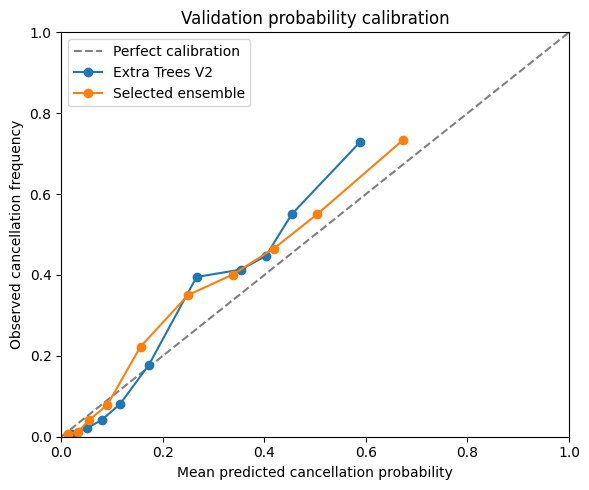

In [40]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

fig, ax = plt.subplots(figsize=(6, 5))

ax.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration",
)

for name, probability in {
    "Extra Trees V2": ft_validation_probabilities["Extra Trees V2"],
    "Selected ensemble": ft_validation_ensemble_probability,
}.items():
    observed_rate, predicted_rate = calibration_curve(
        y_valid,
        probability,
        n_bins=10,
        strategy="quantile",
    )

    ax.plot(
        predicted_rate,
        observed_rate,
        marker="o",
        label=name,
    )

ax.set(
    xlabel="Mean predicted cancellation probability",
    ylabel="Observed cancellation frequency",
    title="Validation probability calibration",
    xlim=(0, 1),
    ylim=(0, 1),
)

ax.legend()
fig.tight_layout()

fig.savefig(
    FT_SAVE_DIR / "validation_calibration.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# 2. Task 1: Forecast Room-Nights Released by Cancellations

We forecast subsequent explicit cancellations among observed pre-arrival
reservations covering each hotel-night, at horizons of 30, 14, 7, and 1 days.

Historical snapshots include only reservations booked by the prediction date
whose terminal status had not yet been recorded and whose arrival remained
in the future. Explicit cancellations count toward the outcome; no-shows do not.

Each booking contributes to its stay nights, excluding departure day.
The primary analysis removes exact duplicates; a separate sensitivity analysis
will examine their effect on room-night counts.

This estimates cancellation-related room-nights, not total available inventory,
occupancy, replacement bookings, or revenue recovered. One row is assumed to
represent one reserved room.

The forecasting model will account for booking age and time remaining until
arrival. Training outcomes must have been recorded by the model's fitting date.

In [41]:
import numpy as np
import pandas as pd

TASK1_HORIZONS = [30, 14, 7, 1]

# Preserve the existing partition boundaries.
TASK1_FIT_CUTOFF = pd.Timestamp(
    train_df["_arrival_date"].max()
)

TASK1_VALID_END = pd.Timestamp(
    valid_df["_arrival_date"].max()
)


def task1_prepare_bookings(source, drop_duplicates=True):
    """Prepare booking records for historical snapshot construction."""

    bookings = source.copy()

    if drop_duplicates:
        bookings = bookings.drop_duplicates().copy()

    guest_count = (
        bookings["adults"]
        + bookings["children"].fillna(0)
        + bookings["babies"]
    )

    nights = (
        bookings["stays_in_weekend_nights"]
        + bookings["stays_in_week_nights"]
    )

    # Retain the team's basic cleaning rules.
    # Zero-night bookings cannot contribute a room-night.
    keep = (
        (guest_count > 0)
        & ~bookings["adr"].lt(0)
        & bookings["lead_time"].ge(0)
        & nights.gt(0)
    )

    bookings = bookings.loc[keep].copy()

    bookings["_arrival"] = pd.to_datetime({
        "year": bookings["arrival_date_year"],
        "month": bookings["arrival_date_month"].map(MONTH_NUM),
        "day": bookings["arrival_date_day_of_month"],
    })

    bookings["_nights"] = (
        bookings["stays_in_weekend_nights"]
        + bookings["stays_in_week_nights"]
    ).astype(int)

    bookings["_departure"] = (
        bookings["_arrival"]
        + pd.to_timedelta(bookings["_nights"], unit="D")
    )

    bookings["_booked"] = (
        bookings["_arrival"]
        - pd.to_timedelta(bookings["lead_time"], unit="D")
    )

    bookings["_status_date"] = pd.to_datetime(
        bookings["reservation_status_date"],
        errors="coerce",
    )

    bookings["_canceled"] = bookings[
        "reservation_status"
    ].eq("Canceled")

    known_terminal_status = bookings["reservation_status"].isin(
        ["Canceled", "Check-Out", "No-Show"]
    )

    valid_dates = (
        bookings["_status_date"].notna()
        & bookings["_status_date"].ge(bookings["_booked"])
    )

    # An explicit pre-arrival cancellation cannot occur after arrival.
    valid_cancellation = (
        ~bookings["_canceled"]
        | bookings["_status_date"].le(bookings["_arrival"])
    )

    bookings = bookings.loc[
        known_terminal_status & valid_dates & valid_cancellation
    ].copy()

    bookings = bookings.reset_index(drop=True)

    # Internal row reference, not a genuine booking identifier.
    bookings["BookingRow"] = np.arange(len(bookings))

    return bookings


# Work only with development-period arrivals at this stage.
task1_original_arrivals = pd.to_datetime({
    "year": raw["arrival_date_year"],
    "month": raw["arrival_date_month"].map(MONTH_NUM),
    "day": raw["arrival_date_day_of_month"],
})

task1_development_raw = raw.loc[
    task1_original_arrivals <= TASK1_VALID_END
].copy()

task1_bookings = task1_prepare_bookings(
    task1_development_raw,
    drop_duplicates=True,
)

print("Task 1 development booking table ready.")
print("Usable booking records:", len(task1_bookings))
print("Training cutoff:", TASK1_FIT_CUTOFF.date())
print("Validation end:", TASK1_VALID_END.date())

Task 1 development booking table ready.
Usable booking records: 69585
Training cutoff: 2017-01-05
Validation end: 2017-05-04


In [42]:
def task1_make_snapshots(
    bookings,
    start,
    end,
    horizons,
    known_outcome_cutoff=None,
):
    """
    Construct eligible booking-night observations at historical origins.

    If known_outcome_cutoff is supplied, restrict source outcomes to those
    recorded by that date. This restriction is for training labels.
    """

    start = pd.Timestamp(start)
    end = pd.Timestamp(end)

    b = bookings.copy()

    if known_outcome_cutoff is not None:
        b = b.loc[
            b["_status_date"] <= pd.Timestamp(known_outcome_cutoff)
        ].copy()

    # Keep bookings whose stays overlap the requested night range.
    b = b.loc[
        (b["_arrival"] <= end)
        & (b["_departure"] > start)
    ].copy()

    # Clip each stay to the requested evaluation window.
    first_night = b["_arrival"].clip(lower=start)

    last_exclusive = b["_departure"].clip(
        upper=end + pd.Timedelta(days=1)
    )

    lengths = (
        last_exclusive - first_night
    ).dt.days.to_numpy(dtype=int)

    # Expand booking records into their individual stay nights.
    positions = np.repeat(np.arange(len(b)), lengths)

    offsets = (
        np.arange(lengths.sum())
        - np.repeat(
            np.cumsum(lengths) - lengths,
            lengths,
        )
    )

    expanded = pd.DataFrame({
        "BookingRow": b["BookingRow"].to_numpy()[positions],
        "hotel": b["hotel"].to_numpy()[positions],

        "Night": (
            first_night.to_numpy()[positions]
            + offsets.astype("timedelta64[D]")
        ),

        "_arrival": b["_arrival"].to_numpy()[positions],
        "_booked": b["_booked"].to_numpy()[positions],
        "_status_date": b["_status_date"].to_numpy()[positions],
        "_canceled": b["_canceled"].to_numpy()[positions],
    })

    parts = []

    for horizon in horizons:
        origin = (
            expanded["Night"]
            - pd.Timedelta(days=int(horizon))
        )

        eligible = (
            # Booking already existed.
            (expanded["_booked"] <= origin)

            # Guest had not yet reached the arrival date.
            & (expanded["_arrival"] > origin)

            # No terminal event had been recorded by end of that date.
            & (expanded["_status_date"] > origin)
        )

        snapshot = expanded.loc[
            eligible,
            ["BookingRow", "hotel", "Night"],
        ].copy()

        snapshot["Horizon"] = int(horizon)
        snapshot["Origin"] = origin.loc[eligible]

        snapshot["days_until_arrival"] = (
            expanded.loc[eligible, "_arrival"]
            - snapshot["Origin"]
        ).dt.days

        snapshot["days_since_booking"] = (
            snapshot["Origin"]
            - expanded.loc[eligible, "_booked"]
        ).dt.days

        # Eligible explicit cancellations happen after the origin and
        # no later than arrival, so they release this reserved room-night.
        snapshot["Target"] = (
            expanded.loc[eligible, "_canceled"].astype(int)
        )

        parts.append(snapshot)

    return pd.concat(parts, ignore_index=True)


print("Historical snapshot builder ready.")

Historical snapshot builder ready.


In [43]:
# Begin training nights far enough into observed coverage that all
# four horizons have origins within that coverage.
TASK1_TRAIN_START = (
    task1_bookings["_arrival"].min()
    + pd.Timedelta(days=max(TASK1_HORIZONS))
)

# Use a common validation-night window across all horizons.
# Even the 30-day origin must be AFTER the training cutoff.
TASK1_VALID_START = (
    TASK1_FIT_CUTOFF
    + pd.Timedelta(days=max(TASK1_HORIZONS) + 1)
)

task1_train_snapshots = task1_make_snapshots(
    task1_bookings,
    start=TASK1_TRAIN_START,
    end=TASK1_FIT_CUTOFF,
    horizons=TASK1_HORIZONS,
    known_outcome_cutoff=TASK1_FIT_CUTOFF,
)

task1_valid_snapshots = task1_make_snapshots(
    task1_bookings,
    start=TASK1_VALID_START,
    end=TASK1_VALID_END,
    horizons=TASK1_HORIZONS,
)

assert not task1_train_snapshots.empty
assert not task1_valid_snapshots.empty

assert (
    task1_valid_snapshots["Origin"] > TASK1_FIT_CUTOFF
).all()

for snapshots in [task1_train_snapshots, task1_valid_snapshots]:
    assert snapshots["days_until_arrival"].gt(0).all()
    assert snapshots["days_since_booking"].ge(0).all()
    assert snapshots["Target"].isin([0, 1]).all()

# Confirm that training outcomes were recorded by the fitting date.
training_booking_rows = (
    task1_train_snapshots["BookingRow"].unique()
)

assert (
    task1_bookings.iloc[training_booking_rows]["_status_date"]
    <= TASK1_FIT_CUTOFF
).all()

summary_rows = []

for partition, snapshots in [
    ("Training", task1_train_snapshots),
    ("Validation", task1_valid_snapshots),
]:
    for horizon, group in snapshots.groupby("Horizon"):
        summary_rows.append({
            "Partition": partition,
            "Horizon": horizon,
            "Snapshot_rows": len(group),
            "Distinct_booking_rows": group["BookingRow"].nunique(),
            "Cancellation_rate": group["Target"].mean(),
        })

task1_snapshot_summary = pd.DataFrame(summary_rows)

print("Training nights:",
      TASK1_TRAIN_START.date(), "to", TASK1_FIT_CUTOFF.date())

print("Validation nights:",
      TASK1_VALID_START.date(), "to", TASK1_VALID_END.date())

display(task1_snapshot_summary.round(4))

task1_snapshot_summary.to_csv(
    FT_SAVE_DIR / "task1_development_snapshot_summary.csv",
    index=False,
)

joblib.dump(
    {
        "bookings": task1_bookings,
        "training": task1_train_snapshots,
        "validation": task1_valid_snapshots,
        "fit_cutoff": TASK1_FIT_CUTOFF,
        "validation_start": TASK1_VALID_START,
        "validation_end": TASK1_VALID_END,
        "horizons": TASK1_HORIZONS,
    },
    FT_SAVE_DIR / "task1_development_snapshots.joblib",
    compress=3,
)

print("Task 1 development snapshots checked and saved.")

Training nights: 2015-07-31 to 2017-01-05
Validation nights: 2017-02-05 to 2017-05-04


,Partition,Horizon,Snapshot_rows,Distinct_booking_rows,Cancellation_rate
0,Training,1,37449,37449,0.0089
1,Training,7,118446,33177,0.0343
2,Training,14,118969,30150,0.0633
3,Training,30,107161,25761,0.1065
4,Validation,1,7475,7475,0.0074
5,Validation,7,23275,6725,0.0243
6,Validation,14,22903,6191,0.0637
7,Validation,30,20676,5282,0.1191


Task 1 development snapshots checked and saved.


## 2.1 Snapshot-Aware Probability Model and Baselines

We reuse the retained logistic-regression configuration from Task 2 and fit it
to the explicit-cancellation snapshot target. Two predictors describe the
prediction moment: days until arrival and days since booking.

This is a separate conditional probability model. Task 2 predicts cancellation
or no-show from booking attributes; Task 1 predicts subsequent explicit
cancellation among reservations still open before arrival.

Training uses one observation per booking-row and prediction date, avoiding
duplicate training observations when different night/horizon combinations
produce the same historical origin.

Predicted probabilities are summed by hotel, stay night, and horizon.
Comparators are training-period cancellation rates by hotel/horizon and a
zero-cancellation forecast.

MAE is the primary count-error measure, supported by RMSE and signed bias.
Forecast methods will be selected per horizon using validation MAE, with RMSE
as the tie-breaker. Final test outcomes remain reserved.

In [44]:
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from threadpoolctl import threadpool_limits

TASK1_AGE_FEATURES = [
    "days_until_arrival",
    "days_since_booking",
]

# Exclude target and post-booking/status fields before model preparation.
TASK1_BASE_COLUMNS = [
    column for column in X_train_raw.columns
    if column not in BookingFeatureEngineer.LEAKY_OR_POST_BOOKING
    and column != "is_canceled"
]


def task1_build_X(bookings, snapshots):
    """Retrieve booking attributes and add prediction-date features."""

    booking_rows = snapshots["BookingRow"].to_numpy(dtype=int)

    X = (
        bookings.iloc[booking_rows][TASK1_BASE_COLUMNS]
        .reset_index(drop=True)
        .copy()
    )

    for feature in TASK1_AGE_FEATURES:
        X[feature] = snapshots[feature].to_numpy(dtype=float)

    assert "Target" not in X.columns
    assert "reservation_status" not in X.columns
    assert "reservation_status_date" not in X.columns

    return X


# A booking may appear under multiple night/horizon combinations
# with the same origin. Train once on each distinct booking-origin pair.
task1_training_examples = (
    task1_train_snapshots
    .drop_duplicates(["BookingRow", "Origin"])
    .reset_index(drop=True)
)

task1_X_fit = task1_build_X(
    task1_bookings,
    task1_training_examples,
)

task1_y_fit = (
    task1_training_examples["Target"]
    .astype(int)
    .reset_index(drop=True)
)

assert task1_y_fit.nunique() == 2

# Reuse the retained LR configuration, with fresh fitted state.
task1_pipeline = clone(
    ft_selected_pipelines["Logistic Regression V1"]
)

task1_preprocessor = (
    task1_pipeline.named_steps["prepare"]
    .named_steps["preprocessing"]
)

# Include the age features in the numeric imputation/scaling branch.
task1_preprocessor.set_params(transformers=[
    (
        name,
        transformer,
        list(columns) + (
            TASK1_AGE_FEATURES if name == "other_num" else []
        ),
    )
    for name, transformer, columns
    in task1_preprocessor.transformers
])

# Historical-rate baseline: learn only from training snapshots.
task1_baseline_rates = (
    task1_train_snapshots
    .groupby(["hotel", "Horizon"])["Target"]
    .mean()
)

task1_global_rate = float(
    task1_train_snapshots["Target"].mean()
)

task1_model_path = (
    FT_SAVE_DIR / "task1_development_probability_model.joblib"
)

task1_model_signature = joblib.hash((
    task1_X_fit,
    task1_y_fit,
    task1_pipeline,
    TASK1_FIT_CUTOFF,
    "native_threads=2",
))

print("Original training snapshot rows:",
      len(task1_train_snapshots))

print("Distinct booking-origin training examples:",
      len(task1_training_examples))

print("Training input shape:", task1_X_fit.shape, flush=True)

if task1_model_path.exists():
    task1_forecaster = joblib.load(task1_model_path)

    if task1_forecaster["signature"] != task1_model_signature:
        raise ValueError(
            "The saved Task 1 model belongs to a different setup. "
            "Use a new checkpoint filename if you changed the experiment."
        )

    print("Loaded saved Task 1 development model.")
else:
    started = time.perf_counter()

    with threadpool_limits(limits=2):
        task1_pipeline.fit(task1_X_fit, task1_y_fit)

    assert np.array_equal(task1_pipeline.classes_, [0, 1])

    task1_forecaster = {
        "signature": task1_model_signature,
        "model": task1_pipeline,
        "baseline_rates": task1_baseline_rates,
        "global_rate": task1_global_rate,
        "fit_cutoff": TASK1_FIT_CUTOFF,
        "base_columns": TASK1_BASE_COLUMNS,
        "age_features": TASK1_AGE_FEATURES,
    }

    joblib.dump(
        task1_forecaster,
        task1_model_path,
        compress=3,
    )

    print(
        "Model fitted and saved in",
        round(time.perf_counter() - started, 1),
        "seconds.",
    )

Original training snapshot rows: 382025
Distinct booking-origin training examples: 368660
Training input shape: (368660, 26)
Model fitted and saved in 31.0 seconds.


In [45]:
def task1_make_nightly_forecasts(
    bookings,
    snapshots,
    forecaster,
    start,
    end,
):
    """Aggregate conditional probabilities and outcomes by hotel-night."""

    hotels = sorted(bookings["hotel"].unique())

    # Include every hotel-night-horizon, even if no eligible bookings exist.
    full_index = pd.MultiIndex.from_product(
        [
            hotels,
            pd.date_range(start, end, freq="D"),
            TASK1_HORIZONS,
        ],
        names=["hotel", "Night", "Horizon"],
    )

    if snapshots.empty:
        nightly = pd.DataFrame(
            0,
            index=full_index,
            columns=[
                "Actual",
                "Snapshot_model",
                "Historical_rate",
                "Eligible_bookings",
            ],
        )
    else:
        X = task1_build_X(bookings, snapshots)

        with threadpool_limits(limits=2):
            probability = forecaster["model"].predict_proba(X)[:, 1]

        rate_index = pd.MultiIndex.from_frame(
            snapshots[["hotel", "Horizon"]]
        )

        historical_probability = (
            forecaster["baseline_rates"]
            .reindex(rate_index)
            .fillna(forecaster["global_rate"])
            .to_numpy()
        )

        contributions = snapshots[
            ["hotel", "Night", "Horizon", "Target"]
        ].copy()

        contributions["Snapshot_model"] = probability
        contributions["Historical_rate"] = historical_probability

        nightly = (
            contributions
            .groupby(["hotel", "Night", "Horizon"])
            .agg(
                Actual=("Target", "sum"),
                Snapshot_model=("Snapshot_model", "sum"),
                Historical_rate=("Historical_rate", "sum"),
                Eligible_bookings=("Target", "size"),
            )
            .reindex(full_index, fill_value=0)
        )

    nightly = nightly.reset_index()

    nightly["Actual"] = nightly["Actual"].astype(int)
    nightly["Eligible_bookings"] = (
        nightly["Eligible_bookings"].astype(int)
    )

    nightly["Zero_forecast"] = 0.0

    return nightly


task1_validation_forecasts = task1_make_nightly_forecasts(
    bookings=task1_bookings,
    snapshots=task1_valid_snapshots,
    forecaster=task1_forecaster,
    start=TASK1_VALID_START,
    end=TASK1_VALID_END,
)

task1_validation_forecasts.to_csv(
    FT_SAVE_DIR / "task1_validation_nightly_forecasts.csv",
    index=False,
)

print("Validation hotel-night-horizon rows:",
      len(task1_validation_forecasts))

display(task1_validation_forecasts.head(8).round(3))

Validation hotel-night-horizon rows: 712


,hotel,Night,Horizon,Actual,Snapshot_model,Historical_rate,Eligible_bookings,Zero_forecast
0,City Hotel,2017-02-05,30,12,9.725,6.300,47,0.0
1,City Hotel,2017-02-05,14,15,8.718,8.137,93,0.0
2,City Hotel,2017-02-05,7,5,5.416,4.596,94,0.0
3,City Hotel,2017-02-05,1,1,1.303,0.396,41,0.0
4,City Hotel,2017-02-06,30,9,8.607,5.496,41,0.0
5,City Hotel,2017-02-06,14,10,6.493,6.912,79,0.0
6,City Hotel,2017-02-06,7,3,4.444,4.303,88,0.0
7,City Hotel,2017-02-06,1,1,1.264,0.261,27,0.0


In [46]:
def task1_count_metrics(nightly, by=("Horizon",)):
    methods = [
        "Snapshot_model",
        "Historical_rate",
        "Zero_forecast",
    ]

    if by:
        groups = nightly.groupby(list(by), sort=True)
    else:
        groups = [((), nightly)]

    records = []

    for key, group in groups:
        key = key if isinstance(key, tuple) else (key,)
        group_labels = dict(zip(by, key))

        actual = group["Actual"].to_numpy(dtype=float)

        for method in methods:
            predicted = group[method].to_numpy(dtype=float)
            error = predicted - actual

            records.append({
                **group_labels,
                "Method": method,
                "MAE": np.abs(error).mean(),
                "RMSE": np.sqrt(np.square(error).mean()),
                "Bias": error.mean(),
                "Actual_mean": actual.mean(),
                "Predicted_mean": predicted.mean(),
                "Hotel_nights": len(group),
            })

    return pd.DataFrame(records)


task1_validation_metrics = task1_count_metrics(
    task1_validation_forecasts
)

task1_validation_by_hotel = task1_count_metrics(
    task1_validation_forecasts,
    by=("hotel", "Horizon"),
)

task1_validation_overall = task1_count_metrics(
    task1_validation_forecasts,
    by=(),
)

print("Validation results by horizon:")
display(task1_validation_metrics.round(4))

print("\nOverall validation results:")
display(task1_validation_overall.round(4))

# Follow the declared rule: lowest MAE, then lowest RMSE.
task1_selected_methods = (
    task1_validation_metrics
    .sort_values(["Horizon", "MAE", "RMSE", "Method"])
    .drop_duplicates("Horizon")
    [["Horizon", "Method", "MAE", "RMSE"]]
    .sort_values("Horizon")
)

task1_method_by_horizon = (
    task1_selected_methods
    .set_index("Horizon")["Method"]
    .to_dict()
)

print("\nSelected forecast method per horizon:")
display(task1_selected_methods.round(4))

task1_validation_metrics.to_csv(
    FT_SAVE_DIR / "task1_validation_metrics_by_horizon.csv",
    index=False,
)

task1_validation_by_hotel.to_csv(
    FT_SAVE_DIR / "task1_validation_metrics_by_hotel.csv",
    index=False,
)

task1_validation_overall.to_csv(
    FT_SAVE_DIR / "task1_validation_metrics_overall.csv",
    index=False,
)

joblib.dump(
    task1_method_by_horizon,
    FT_SAVE_DIR / "task1_selected_method_by_horizon.joblib",
)

print("Task 1 validation results and method choices saved.")

Validation results by horizon:


,Horizon,Method,MAE,RMSE,Bias,Actual_mean,Predicted_mean,Hotel_nights
0,1,Snapshot_model,1.1304,1.3743,1.0012,0.3090,1.3102,178
1,1,Historical_rate,0.4828,0.6155,0.0659,0.3090,0.3749,178
2,1,Zero_forecast,0.3090,0.6829,-0.3090,0.3090,0.0000,178
3,7,Snapshot_model,2.1291,2.7182,1.4804,3.1742,4.6545,178
4,7,Historical_rate,2.3141,2.9941,1.5620,3.1742,4.7362,178
5,7,Zero_forecast,3.1742,3.9866,-3.1742,3.1742,0.0000,178
6,14,Snapshot_model,2.4066,3.1318,-1.2391,8.1966,6.9575,178
7,14,Historical_rate,2.6942,3.3658,0.4590,8.1966,8.6557,178
8,14,Zero_forecast,8.1966,9.6980,-8.1966,8.1966,0.0000,178
9,30,Snapshot_model,3.6254,4.6878,0.2213,13.8315,14.0528,178



Overall validation results:


,Method,MAE,RMSE,Bias,Actual_mean,Predicted_mean,Hotel_nights
0,Snapshot_model,2.3229,3.2039,0.3659,6.3778,6.7438,712
1,Historical_rate,2.4539,3.4642,0.3007,6.3778,6.6785,712
2,Zero_forecast,6.3778,9.4211,-6.3778,6.3778,0.0000,712



Selected forecast method per horizon:


,Horizon,Method,MAE,RMSE
2,1,Zero_forecast,0.3090,0.6829
3,7,Snapshot_model,2.1291,2.7182
6,14,Snapshot_model,2.4066,3.1318
9,30,Snapshot_model,3.6254,4.6878


Task 1 validation results and method choices saved.


## 2.2 Freeze the horizon policy, residual bands, and duplicate sensitivity

Select one forecast method per horizon using validation MAE, with RMSE as the
tie-breaker. Nominal 90% bands use validation residual quantiles by hotel/horizon.
The duplicate check changes counting only: the model and policy remain fixed.
All of these choices precede the final refits and test evaluation.


In [47]:
import numpy as np
import pandas as pd
import joblib


def task1_apply_frozen_policy(nightly, intervals=False):
    result = nightly.copy()
    result["Selected_forecast"] = np.nan

    for horizon, method in task1_method_by_horizon.items():
        mask = result["Horizon"].eq(int(horizon))
        result.loc[mask, "Selected_forecast"] = (
            result.loc[mask, method].to_numpy()
        )

    assert result["Selected_forecast"].notna().all()

    if intervals:
        keys = pd.MultiIndex.from_frame(
            result[["hotel", "Horizon"]]
        )
        adjustments = task1_interval_adjustments.reindex(keys)

        assert adjustments[["Residual_q05", "Residual_q95"]].notna().all().all()

        # Round count intervals outward and prevent negative counts.
        result["Lower90"] = np.floor(np.maximum(
            0,
            result["Selected_forecast"].to_numpy()
            + adjustments["Residual_q05"].to_numpy(),
        ))

        result["Upper90"] = np.ceil(np.maximum(
            0,
            result["Selected_forecast"].to_numpy()
            + adjustments["Residual_q95"].to_numpy(),
        ))

        result["Covered90"] = (
            result["Actual"].ge(result["Lower90"])
            & result["Actual"].le(result["Upper90"])
        )

    return result


# Validation residual bands for the frozen primary policy.
task1_validation_selected = task1_apply_frozen_policy(
    task1_validation_forecasts
)

interval_rows = []

for (hotel, horizon), group in (
    task1_validation_selected.groupby(["hotel", "Horizon"])
):
    residual = group["Actual"] - group["Selected_forecast"]

    interval_rows.append({
        "hotel": hotel,
        "Horizon": int(horizon),
        "Residual_q05": float(residual.quantile(0.05)),
        "Residual_q95": float(residual.quantile(0.95)),
        "Calibration_nights": len(group),
    })

task1_interval_adjustments = (
    pd.DataFrame(interval_rows)
    .set_index(["hotel", "Horizon"])
)

# Counting sensitivity: hold model and policy fixed.
task1_duplicate_bookings = task1_prepare_bookings(
    task1_development_raw,
    drop_duplicates=False,
)

task1_duplicate_snapshots = task1_make_snapshots(
    task1_duplicate_bookings,
    TASK1_VALID_START,
    TASK1_VALID_END,
    TASK1_HORIZONS,
)

task1_duplicate_forecasts = task1_make_nightly_forecasts(
    task1_duplicate_bookings,
    task1_duplicate_snapshots,
    task1_forecaster,
    TASK1_VALID_START,
    TASK1_VALID_END,
)

task1_duplicate_forecasts = task1_apply_frozen_policy(
    task1_duplicate_forecasts
)

sensitivity_rows = []

for case, nightly in [
    ("Duplicates removed", task1_validation_selected),
    ("Duplicates counted separately", task1_duplicate_forecasts),
]:
    for horizon, group in nightly.groupby("Horizon"):
        error = group["Selected_forecast"] - group["Actual"]

        sensitivity_rows.append({
            "Counting_assumption": case,
            "Horizon": int(horizon),
            "Method": task1_method_by_horizon[int(horizon)],
            "MAE": error.abs().mean(),
            "Bias": error.mean(),
            "Actual_mean": group["Actual"].mean(),
            "Predicted_mean": group["Selected_forecast"].mean(),
        })

task1_duplicate_sensitivity = pd.DataFrame(sensitivity_rows)

task1_duplicate_sensitivity.to_csv(
    FT_SAVE_DIR / "task1_validation_duplicate_count_sensitivity.csv",
    index=False,
)

task1_interval_adjustments.to_csv(
    FT_SAVE_DIR / "task1_validation_residual_bands.csv"
)

joblib.dump(
    {
        "horizons": TASK1_HORIZONS,
        "method_by_horizon": task1_method_by_horizon,
        "interval_adjustments": task1_interval_adjustments,
        "nominal_coverage": 0.90,
        "primary_counting_assumption": "Exact duplicates removed",
        "outcome": "Subsequent explicit pre-arrival cancellation",
    },
    FT_SAVE_DIR / "task1_forecast_policy.joblib",
)

print("Validation sensitivity saved. Forecast policy frozen.")
display(task1_duplicate_sensitivity.round(4))

Validation sensitivity saved. Forecast policy frozen.


,Counting_assumption,Horizon,Method,MAE,Bias,Actual_mean,Predicted_mean
0,Duplicates removed,1,Zero_forecast,0.3090,-0.3090,0.3090,0.0000
1,Duplicates removed,7,Snapshot_model,2.1291,1.4804,3.1742,4.6545
2,Duplicates removed,14,Snapshot_model,2.4066,-1.2391,8.1966,6.9575
3,Duplicates removed,30,Snapshot_model,3.6254,0.2213,13.8315,14.0528
4,Duplicates counted separately,1,Zero_forecast,0.4045,-0.4045,0.4045,0.0000
5,Duplicates counted separately,7,Snapshot_model,2.6552,1.5843,3.8708,5.4551
6,Duplicates counted separately,14,Snapshot_model,3.0429,-1.5335,9.9213,8.3878
7,Duplicates counted separately,30,Snapshot_model,4.4869,0.1425,17.0337,17.1762


# 3. Final refits with the selected settings fixed

Task 2 refits both ensemble members on the combined original training and validation
partitions. Task 1 uses only eligible outcomes recorded by the final May 4, 2017
cutoff. The selected model configurations, equal ensemble weights, threshold 0.45,
counting assumption, horizon methods, and interval rules remain fixed.


In [48]:
from sklearn.base import clone
from threadpoolctl import threadpool_limits
import time


def final_fit_or_load(pipeline, X, y, filename):
    """Cache a final fit without using test outcomes."""

    prototype = clone(pipeline)
    signature = joblib.hash((prototype, X, y, "native_threads=2"))
    path = FT_SAVE_DIR / filename

    if path.exists():
        saved = joblib.load(path)

        if saved["signature"] != signature:
            raise ValueError(
                f"Different final-fit setup for {filename}. "
                "Check the inputs before proceeding."
            )

        print(f"Loaded {filename}", flush=True)
        return saved["model"]

    started = time.perf_counter()
    print(f"Fitting {filename}...", flush=True)

    with threadpool_limits(limits=2):
        fitted = prototype.fit(X, y)

    joblib.dump(
        {"signature": signature, "model": fitted},
        path,
        compress=3,
    )

    print(
        f"Saved {filename}: "
        f"{time.perf_counter() - started:.1f}s",
        flush=True,
    )

    return fitted


# TASK 2: combine the original training and validation partitions.
ft_X_development = pd.concat(
    [X_train_raw, X_valid_raw],
    ignore_index=True,
)

ft_y_development = pd.concat(
    [y_train, y_valid],
    ignore_index=True,
)

ft_final_models = {}

for name, filename in [
    ("Extra Trees V2", "final_task2_extra_trees.joblib"),
    ("MLP V0", "final_task2_mlp.joblib"),
]:
    ft_final_models[name] = final_fit_or_load(
        ft_selected_pipelines[name],
        ft_X_development,
        ft_y_development,
        filename,
    )


# TASK 1: construct the final training data using only outcomes
# recorded by the end of the development period.
TASK1_FINAL_FIT_CUTOFF = TASK1_VALID_END

task1_final_bookings = task1_prepare_bookings(
    raw,
    drop_duplicates=True,
)

task1_final_train_snapshots = task1_make_snapshots(
    task1_final_bookings,
    start=TASK1_TRAIN_START,
    end=TASK1_FINAL_FIT_CUTOFF,
    horizons=TASK1_HORIZONS,
    known_outcome_cutoff=TASK1_FINAL_FIT_CUTOFF,
)

task1_final_examples = (
    task1_final_train_snapshots
    .drop_duplicates(["BookingRow", "Origin"])
    .reset_index(drop=True)
)

task1_final_X = task1_build_X(
    task1_final_bookings,
    task1_final_examples,
)

task1_final_y = task1_final_examples["Target"].astype(int)

print(
    "\nTask 1 final training examples:",
    len(task1_final_examples),
    flush=True,
)

task1_final_model = final_fit_or_load(
    task1_forecaster["model"],
    task1_final_X,
    task1_final_y,
    "final_task1_snapshot_logistic.joblib",
)

# Update historical rates from eligible development snapshots.
task1_final_forecaster = {
    "model": task1_final_model,
    "baseline_rates": (
        task1_final_train_snapshots
        .groupby(["hotel", "Horizon"])["Target"]
        .mean()
    ),
    "global_rate": float(
        task1_final_train_snapshots["Target"].mean()
    ),
    "fit_cutoff": TASK1_FINAL_FIT_CUTOFF,
    "base_columns": TASK1_BASE_COLUMNS,
    "age_features": TASK1_AGE_FEATURES,
}

joblib.dump(
    task1_final_forecaster,
    FT_SAVE_DIR / "task1_final_forecaster.joblib",
    compress=3,
)

print("\nFinal refits complete. Test outcomes have not been scored yet.")

Fitting final_task2_extra_trees.joblib...
Saved final_task2_extra_trees.joblib: 55.7s
Fitting final_task2_mlp.joblib...
Saved final_task2_mlp.joblib: 25.0s

Task 1 final training examples: 451745
Fitting final_task1_snapshot_logistic.joblib...
Saved final_task1_snapshot_logistic.joblib: 25.2s

Final refits complete. Test outcomes have not been scored yet.


## 3.1 Final reserved-period performance assessment

The cell below produced the recorded final performance tables. Classification
comparators use the same development refit and do not trigger further selection.
Task 1 test origins strictly follow its final fitting cutoff. Do not change model
or policy settings in response to these results.


In [49]:
from IPython.display import display

# ---------- TASK 2: final classifier evaluation ----------

ft_test_member_probabilities = {}

with threadpool_limits(limits=2):
    for name, model in ft_final_models.items():
        assert np.array_equal(model.classes_, [0, 1])

        ft_test_member_probabilities[name] = (
            model.predict_proba(X_test_raw)[:, 1]
        )

ft_final_test_probability = np.mean(
    np.column_stack([
        ft_test_member_probabilities["Extra Trees V2"],
        ft_test_member_probabilities["MLP V0"],
    ]),
    axis=1,
)

ft_frozen_decision = joblib.load(
    FT_SAVE_DIR / "classification_decision_policy.joblib"
)

ft_test_threshold = float(ft_frozen_decision["threshold"])

ft_test_baseline_probability = np.full(
    len(y_test),
    float(ft_y_development.mean()),
)

ft_final_test_comparison = pd.DataFrame({
    "Training-rate baseline": ft_classification_metrics(
        y_test,
        ft_test_baseline_probability,
        threshold=0.5,
    ),
    "Original Extra Trees configuration, threshold 0.50":
        ft_classification_metrics(
            y_test,
            ft_test_member_probabilities["Extra Trees V2"],
            threshold=0.5,
        ),
    "Selected ensemble, threshold 0.50":
        ft_classification_metrics(
            y_test,
            ft_final_test_probability,
            threshold=0.5,
        ),
    f"FINAL ensemble, threshold {ft_test_threshold:.2f}":
        ft_classification_metrics(
            y_test,
            ft_final_test_probability,
            threshold=ft_test_threshold,
        ),
}).T

print("TASK 2 — FINAL TEST RESULTS")
display(ft_final_test_comparison.round(4))

ft_final_test_comparison.to_csv(
    FT_SAVE_DIR / "task2_final_test_metrics.csv"
)

pd.DataFrame({
    "Actual": np.asarray(y_test),
    "Cancel_probability": ft_final_test_probability,
    "Predicted": (
        ft_final_test_probability > ft_test_threshold
    ).astype(int),
}).to_csv(
    FT_SAVE_DIR / "task2_final_test_predictions.csv",
    index=False,
)


# ---------- TASK 1: final nightly forecast evaluation ----------

TASK1_TEST_START = (
    TASK1_FINAL_FIT_CUTOFF
    + pd.Timedelta(days=max(TASK1_HORIZONS) + 1)
)

TASK1_TEST_END = pd.Timestamp(
    test_df["_arrival_date"].max()
)

task1_test_snapshots = task1_make_snapshots(
    task1_final_bookings,
    start=TASK1_TEST_START,
    end=TASK1_TEST_END,
    horizons=TASK1_HORIZONS,
)

assert (
    task1_test_snapshots["Origin"] > TASK1_FINAL_FIT_CUTOFF
).all()

task1_final_test_forecasts = task1_make_nightly_forecasts(
    bookings=task1_final_bookings,
    snapshots=task1_test_snapshots,
    forecaster=task1_final_forecaster,
    start=TASK1_TEST_START,
    end=TASK1_TEST_END,
)

task1_final_test_forecasts = task1_apply_frozen_policy(
    task1_final_test_forecasts,
    intervals=True,
)


def task1_final_report(nightly, by_hotel=False):
    group_columns = (
        ["hotel", "Horizon"] if by_hotel else ["Horizon"]
    )

    rows = []

    for key, group in nightly.groupby(group_columns):
        key = key if isinstance(key, tuple) else (key,)
        labels = dict(zip(group_columns, key))
        horizon = int(labels["Horizon"])

        error = group["Selected_forecast"] - group["Actual"]

        rows.append({
            **labels,
            "Method": task1_method_by_horizon[horizon],
            "MAE": error.abs().mean(),
            "Historical_MAE": (
                group["Historical_rate"] - group["Actual"]
            ).abs().mean(),
            "Zero_MAE": group["Actual"].abs().mean(),
            "RMSE": np.sqrt(np.square(error).mean()),
            "Bias": error.mean(),
            "Coverage90": group["Covered90"].mean(),
            "Mean_band_width": (
                group["Upper90"] - group["Lower90"]
            ).mean(),
            "Hotel_nights": len(group),
        })

    return pd.DataFrame(rows)


task1_final_test_metrics = task1_final_report(
    task1_final_test_forecasts
)

task1_final_test_by_hotel = task1_final_report(
    task1_final_test_forecasts,
    by_hotel=True,
)

print(
    "\nTASK 1 — FINAL TEST NIGHTS:",
    TASK1_TEST_START.date(),
    "to",
    TASK1_TEST_END.date(),
)

display(task1_final_test_metrics.round(4))

task1_final_test_metrics.to_csv(
    FT_SAVE_DIR / "task1_final_test_metrics.csv",
    index=False,
)

task1_final_test_by_hotel.to_csv(
    FT_SAVE_DIR / "task1_final_test_metrics_by_hotel.csv",
    index=False,
)

task1_final_test_forecasts.to_csv(
    FT_SAVE_DIR / "task1_final_test_nightly_forecasts.csv",
    index=False,
)

print("\nBoth final evaluations completed and saved.")
print("Keep the selected settings fixed.")

TASK 2 — FINAL TEST RESULTS


,ROC_AUC,Brier,Precision,Recall,F1,F0.5,TN,FP,FN,TP
Training-rate baseline,0.5000,0.2344,0.0000,0.0000,0.0000,0.0000,11162.0,0.0,5926.0,0.0
"Original Extra Trees configuration, threshold 0.50",0.7961,0.1734,0.6763,0.2933,0.4091,0.5362,10330.0,832.0,4188.0,1738.0
"Selected ensemble, threshold 0.50",0.8040,0.1703,0.6391,0.3966,0.4894,0.5694,9835.0,1327.0,3576.0,2350.0
"FINAL ensemble, threshold 0.45",0.8040,0.1703,0.6090,0.5196,0.5607,0.5887,9185.0,1977.0,2847.0,3079.0



TASK 1 — FINAL TEST NIGHTS: 2017-06-04 to 2017-08-31


,Horizon,Method,MAE,Historical_MAE,Zero_MAE,RMSE,Bias,Coverage90,Mean_band_width,Hotel_nights
0,1,Zero_forecast,0.2809,0.4652,0.2809,0.5996,-0.2809,0.9831,1.5000,178
1,7,Snapshot_model,1.7456,3.2066,2.4045,2.1376,1.1221,0.9944,5.9607,178
2,14,Snapshot_model,2.1857,4.5971,6.6236,2.8446,-0.9854,0.9438,9.2360,178
3,30,Snapshot_model,3.9414,6.0855,13.2921,5.0549,1.0784,0.9382,15.6404,178



Both final evaluations completed and saved.
Keep the selected settings fixed.


# 4. Results, interpretation, and limitations

## 5. Fine-Tune the System

**Owner:** Antonin Laferrière-Mailfait  
**Implementation:** `05_Fine_Tune_and_Forecast_Antonin.ipynb`

### 5.1 Scope and evaluation design

This section continues from the team's preparation, chronological model comparison, and four-model shortlist. Task 2 predicts the binary `is_canceled` outcome, which includes both explicit cancellations and no-shows. The additional Task 1 implementation forecasts room-nights released by subsequent explicit pre-arrival cancellations among observed reservations.

For Task 2, we preserved the team's cleaning rules, feature versions, and chronological partitions: 56,132 training bookings, 14,009 validation bookings, and 17,088 test bookings. Five expanding-window folds were constructed within the training period using unique arrival dates. Each fold trained on earlier arrivals and evaluated on a subsequent period. Feature engineering, imputation, outlier capping, category encoding, and scaling were fitted within each fold's pipeline.

Mean CV ROC-AUC was the model-selection criterion. We also recorded fold standard deviation, precision, recall, F1, and Brier score. Classification metrics initially used the default 0.5 decision boundary. CV means are averages of the five fold metrics; the accompanying standard deviations describe variation across periods, not confidence intervals.

### 5.2 Randomized tuning of models and transformations

We used randomized parameter sampling with the existing five chronological folds. To make the experiments reproducible and recoverable, we used random seed 67 and saved results after every completed fold. An initial broader Extra Trees search was interrupted because individual fits were too expensive; its incomplete results were not used to select a winner. The completed search used a restricted computational budget.

| Shortlisted configuration | Randomized alternatives | Untuned reference also evaluated? | Original mean CV AUC | Retained mean CV AUC |
|---|---:|---|---:|---:|
| Extra Trees V2 | 6 | Yes | 0.8170 | 0.8170 |
| Logistic Regression V1 | 3 | Yes | 0.7984 | 0.7993 |
| Histogram Gradient Boosting V2 | 2 | Yes | 0.7932 | 0.7983 |
| MLP V0 | 2 | Yes | 0.8130 | 0.8130 |

Feature-version labels refer to the existing feature sets. V1 removes `is_domestic` while retaining `country`; V2 additionally introduces estimated stay value (`adr × total_nights`).

The Extra Trees search varied depth, minimum leaf size, and class weighting, while fixing 90 trees and square-root feature sampling to control runtime. It jointly explored no outlier capping versus 99th- and 99.5th-percentile capping, median versus mean numeric imputation, and rare-category minimum frequencies. These imputation choices apply to missing values reaching the numeric imputers; they do not override domain-based replacements already performed inside the feature engineer.

Logistic regression tuning explored regularization strength, class weighting, and rare-category grouping. Boosting tuning explored learning rate, iteration count, leaf count, minimum leaf size, and L2 regularization. MLP tuning explored hidden-layer size, weight regularization, and initial learning rate, retaining the existing 90-iteration maximum and early stopping.

The retained configurations were:

- **Extra Trees V2:** original settings: 90 trees, maximum depth 18, minimum leaf size 4, square-root feature sampling, and no class weighting. None of the six completed alternatives exceeded its original mean CV AUC.
- **Logistic Regression V1:** `C = 0.4340645213116581`, no class weighting, and rare-category minimum frequency 100. The AUC improvement was small.
- **Histogram Gradient Boosting V2:** learning rate 0.05, 60 maximum iterations, 15 maximum leaf nodes, minimum leaf size 50, and L2 regularization 0.
- **MLP V0:** one hidden layer of 48 neurons, `alpha = 0.01142030649919016`, and initial learning rate 0.001. Its observed AUC improvement was negligible at four-decimal precision.

These were bounded searches, not evidence of exhaustive optimization. We retained original settings whenever the completed alternatives did not improve the declared criterion.

### 5.3 Ensemble comparison

We evaluated two predefined equal-weight soft-voting ensembles using cancellation probabilities for the same held-out bookings in each chronological fold. Constituent pipelines were fitted independently within each fold. We compared the two ensembles with the retained individual configurations.

| System | Mean CV ROC-AUC | Fold SD | Precision | Recall | F1 | Brier |
|---|---:|---:|---:|---:|---:|---:|
| Extra Trees + MLP | **0.8214** | 0.0737 | 0.7440 | 0.2743 | 0.3796 | 0.1408 |
| All four models | 0.8203 | 0.0743 | 0.7431 | 0.2640 | 0.3662 | 0.1420 |
| Extra Trees V2 | 0.8170 | 0.0778 | 0.7634 | 0.2642 | 0.3625 | **0.1383** |
| MLP V0 | 0.8130 | 0.0736 | 0.7068 | 0.2919 | 0.3971 | 0.1492 |
| Logistic Regression V1 | 0.7993 | 0.0863 | 0.6695 | 0.2693 | 0.3671 | 0.1478 |
| Histogram Gradient Boosting V2 | 0.7983 | 0.0836 | 0.7371 | 0.2670 | 0.3590 | 0.1490 |

We selected the Extra Trees–MLP ensemble by mean CV ROC-AUC. Its 0.0044 improvement over Extra Trees indicates better observed risk ranking, while Extra Trees retained the lowest CV Brier error. The ensemble therefore did not dominate every measure.

### 5.4 Validation, threshold choice, and final Task 2 evaluation

The selected ensemble was fitted on the original training partition and evaluated on the separate validation period. Validation ROC-AUC was 0.8346 and Brier score was 0.1474. A reliability plot showed imperfect calibration, including underprediction in several middle-to-high probability groups.

Because the project emphasizes avoiding false cancellation flags, we selected a decision threshold by maximizing validation F0.5 over the fixed grid 0.05, 0.10, …, 0.95. F0.5 emphasizes precision but is a development proxy, not an estimated hotel cost function. The selected threshold was **0.45**, with the rule `predicted probability > 0.45`.

After freezing the configurations, equal ensemble weights, and threshold, we refitted both constituent pipelines on all 70,141 development bookings and evaluated the reserved test partition.

| System / decision rule | Test ROC-AUC | Brier | Precision | Recall | F1 | F0.5 |
|---|---:|---:|---:|---:|---:|---:|
| Development-rate probability baseline | 0.5000 | 0.2344 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| Original Extra Trees configuration, threshold 0.50 | 0.7961 | 0.1734 | 0.6763 | 0.2933 | 0.4091 | 0.5362 |
| Selected ensemble, threshold 0.50 | 0.8040 | 0.1703 | 0.6391 | 0.3966 | 0.4894 | 0.5694 |
| **Final ensemble, threshold 0.45** | **0.8040** | **0.1703** | **0.6090** | **0.5196** | **0.5607** | **0.5887** |

The final operating point produced 9,185 true negatives, 1,977 false positives, 2,847 false negatives, and 3,079 true positives. Relative to the ensemble at threshold 0.50, it detected 729 additional cancellations/no-shows with 650 additional false positives. Threshold changes affect decisions, not ROC-AUC or Brier score.

The final ensemble improved observed test AUC and probability error relative to the original Extra Trees configuration. However, precision of 60.9% means that approximately 39.1% of cancellation flags were false alarms. The system supports prioritizing investigation or confirmation; the results do not justify automatically releasing flagged rooms for resale. No model or threshold changes were made in response to these test results.

### 5.5 Task 1 extension: cancellation-related room-night forecasting

**Forecast target.** We estimated subsequent explicit pre-arrival cancellations among observed reservations still open at a historical prediction date and covering a particular hotel-night. This differs from total hotel availability: capacity, replacement bookings, and complete inventory were unavailable. No-shows were excluded from this target.

**Snapshot construction.** Estimated booking date was reconstructed as arrival date minus lead time. Stays were expanded into nights, excluding departure day. A booking-night was eligible if it had already been booked, arrival was still in the future, and its terminal status had not yet been recorded at the end of the prediction date. Cancellations already known at that date were excluded. Dates were treated as end-of-day cutoffs because exact timestamps were unavailable.

**Time separation.** Initial training nights ran from July 31, 2015 through January 5, 2017, using only terminal outcomes recorded by that fitting cutoff. The common validation-night window was February 5–May 4, 2017, ensuring even 30-day forecast origins followed the training cutoff. Initial training contained 382,025 booking-night-horizon rows, reduced to 368,660 distinct booking-row/origin observations for model fitting.

**Conditional model.** We reused the retained logistic-regression configuration and fitted fresh weights to the explicit-cancellation snapshot target. We added days until arrival and days since booking. Outcome/status fields and other previously excluded timing-risk columns were withheld from the predictors. This was one fixed conditional-model fit, not another Task 1 hyperparameter search.

The conditional probabilities were summed by hotel, night, and horizon. We compared this forecast with training-period cancellation rates by hotel/horizon and a zero-cancellation forecast. Threshold 0.45 was not applied to the count forecast.

**Validation policy.** We selected the lowest-MAE method per horizon, with RMSE as the tie-breaker. The zero forecast was selected at one day; the snapshot model was selected at seven, fourteen, and thirty days. The zero forecast is a conservative count prediction selected for MAE, not evidence that cancellations are impossible.

**Duplicate sensitivity.** We held the risk model, historical rates, and selected methods fixed while counting identical records separately. Validation MAE increased from 0.3090 to 0.4045 at one day, 2.1291 to 2.6552 at seven days, 2.4066 to 3.0429 at fourteen days, and 3.6254 to 4.4869 at thirty days. This shows sensitivity to the counting assumption; it does not establish whether duplicate rows are database repeats or genuine separate reservations.

**Final refit and evaluation.** We refitted the conditional model using 451,745 distinct booking-row/origin observations with outcomes recorded by May 4, 2017. The selected methods were unchanged. Test nights ran from June 4–August 31, 2017; even the earliest 30-day test origin followed the final fitting cutoff. Evaluation covered 178 hotel-nights per horizon, or 712 hotel-night-horizon records.

| Horizon | Frozen method | Test MAE | Historical-rate MAE | Zero-forecast MAE | RMSE | Bias |
|---|---|---:|---:|---:|---:|---:|
| 1 day | Zero forecast | 0.2809 | 0.4652 | 0.2809 | 0.5996 | −0.2809 |
| 7 days | Snapshot model | 1.7456 | 3.2066 | 2.4045 | 2.1376 | +1.1221 |
| 14 days | Snapshot model | 2.1857 | 4.5971 | 6.6236 | 2.8446 | −0.9854 |
| 30 days | Snapshot model | 3.9414 | 6.0855 | 13.2921 | 5.0549 | +1.0784 |

Bias is forecast minus actual. Averaging equally across the four horizons, the frozen policy's test MAE was approximately **2.0384**, compared with **3.5886** for historical rates: approximately **43.2% lower error**. These averages combine equally sized horizon groups and are calculated from the displayed rounded results.

**Uncertainty bands.** We used hotel/horizon-specific 5th and 95th percentiles of validation residuals (actual minus selected forecast), rounded count bounds outward, and clipped lower bounds at zero. These are nominal 90% empirical error bands, not formal coverage guarantees.

| Horizon | Test coverage | Mean band width, room-nights |
|---|---:|---:|
| 1 day | 98.31% | 1.5000 |
| 7 days | 99.44% | 5.9607 |
| 14 days | 94.38% | 9.2360 |
| 30 days | 93.82% | 15.6404 |

Coverage exceeded 90% in this test period, with relatively wide bands, particularly at thirty days. We did not tighten the bands after inspecting test coverage.

### 5.6 Assumptions and limitations

- The data represent two Portuguese hotels in 2015–2017; transfer to other properties or current booking behavior is untested.
- The team's earlier exploration examined the full raw dataset. Final test performance was reserved for the final assessment, but the project was not fully blind to the test-period data throughout every earlier exploratory stage.
- Task 2 follows the team's arrival-date holdout protocol. It is a retrospective classification benchmark, not a fully reconstructed booking-time deployment backtest. Task 1 additionally enforces fitting cutoffs, outcome availability, and later forecast origins.
- Snapshot reconstruction remains partial: many attributes are final stored values. Excluding known timing-risk features reduces leakage risk but does not establish that every retained attribute, including deposit and historical-booking fields, was recorded identically at the historical prediction moment.
- There is no genuine booking identifier. Duplicate interpretation and the assumption of one room per row directly affect room counts.
- Task 1 concerns observed, open pre-arrival reservations. It does not predict future bookings, cancellations already recorded, no-show releases, total occupancy, or rooms remaining unsold after replacement demand.
- The conditional forecast model and its historical baseline have different weighting: model fitting uses unique booking/origin observations, while historical rates use room-night exposure. The model is a practical extension whose configuration was reused from Task 2 rather than separately optimized.
- The one-day zero forecast minimizes validation MAE but systematically understates nonzero cancellation counts. Longer-horizon forecasts also retain signed bias.
- Hotel-night errors and repeated booking contributions are temporally correlated. Fold SDs and empirical interval coverage should not be interpreted as independent-sample statistical guarantees.
- Interval residuals came from the earlier validation forecast, before the final refit. The resulting bands have no formal guarantee under changing model fits or booking patterns.
- Small search budgets limit conclusions about optimality. The ensemble's small AUC gains were observed, not demonstrated statistically significant.
- Cancellation prediction does not demonstrate revenue recovered or safe overbooking. Capacity information, richer historical snapshots, and an operational pilot would be required to assess those business outcomes.
- Task 3, cancellation timing prediction, was not implemented in this contribution.

All selected model settings, ensemble weights, decision thresholds, horizon policies, counting assumptions, and interval rules were frozen before final performance assessment. No adjustments were made using the final test results.


## Submission and reproduction notes

The final data fits and evaluations were executed in Colab; those recorded outputs
are preserved above. This submission edit was checked for Python syntax, notebook
structure, and exact preservation of the retained modeling cells and their outputs.
The full real-data workflow was not rerun during cleanup because the CSV and Drive
checkpoints were not included with the uploaded notebook.

The original team notebooks are the source of the shared preparation definitions.
This file contains the prerequisite definitions and completed contribution, avoiding
the need to rerun the entire earlier exploratory and model-shortlisting notebook.
The final discussion distinguishes the retrospective Task 2 split from the partially
reconstructed historical snapshots used by Task 1.

For GitHub, upload this file as `notebooks/05_Fine_Tune_and_Forecast_Antonin.ipynb`
and paste the fine-tuning write-up into README Section 5. Keep the final settings
fixed; Task 3 remains a potential addition rather than a completed deliverable.
